[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_DepolarisingNoiseCertified_Du2021.ipynb)

# Depolarising noise as a certified defence of a quantum classifier: Du et al. (2021) step by step

**Paper.** Yuxuan Du, Min-Hsiu Hsieh, Tongliang Liu, Dacheng Tao and Nana Liu,
*Quantum noise protects quantum classifiers against adversaries*, Physical Review Research **3**, 023153 (2021),
DOI [10.1103/PhysRevResearch.3.023153](https://doi.org/10.1103/PhysRevResearch.3.023153), arXiv [2003.09416](https://arxiv.org/abs/2003.09416).

**What this notebook does.** It rebuilds the whole chain of the paper on a classical computer: a two-qubit variational classifier for
Iris (Setosa vs Versicolour, amplitude encoding, trained exactly as in the paper), the **exact depolarising channel**
(checked against the Qiskit-Aer density-matrix simulator), the statements of the paper that can be tested numerically
(Eq. 10, Lemma 1, Proposition 1, the quantum differential-privacy bound of Lemma 2, the certified trace-distance radius of
Theorem 1 / Corollary 1 / Theorem 2, Theorem 4), the paper's worked example (Table I, Figs. 5 and 6), the accuracy-under-attack
experiment of Fig. 8, and a comparison with **classical randomised smoothing** trained on the same inputs.
The attacks are deliberately *adaptive*: besides the paper-style iterative FGSM that estimates its gradient from
measurement shots, we run the same attack with the exact gradient of the noisy channel, with expectation over transformation
(EOT), a margin PGD with restarts and an exhaustive optimal attack, so that "robustness" that only comes from noisy gradients
(gradient masking) is detected rather than celebrated.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (config cell) is a demonstration that
finishes in a few minutes; set it to `False` for the full budgets (5 seeds, 50-step attacks on 15 budgets, 100 shot-repetitions,
32-draw EOT, 40 000 random state pairs). No GPU, no account, no download and no Hugging Face token: the data are the Iris
flowers bundled with scikit-learn.

**What you get at the end.** Training curves, the drawn circuits (with and without the channel), exact tests of every
formula, certified radii checked against explicit worst-case quantum states and against attacks, the Fig. 8 curves for four
different attackers, a classical baseline, and a table with one verdict per claim of the paper.


## The paper in one page

* **Problem.** Classifiers can be fooled by small, worst-case perturbations of their input (adversarial examples). For a quantum
  classifier the input is a quantum state and "small" means small **trace distance** `tau(sigma, rho) = Tr|rho - sigma| / 2`.
* **Idea.** Put a **depolarising channel** `N_p(S) = p I/D + (1-p) S` into the circuit. Every unitary is unital, so the noisy score is
  simply `y~_k = p/K + (1-p) y_k` (Eq. 10), whatever the circuit and wherever the channels sit; several channels combine to
  `p = 1 - prod(1 - p_i)`.
* **Claims.**
  1. *Lemma 1.* The winning class of the noisy circuit equals that of the noiseless one.
  2. *Proposition 1.* With `N` shots the label survives with probability `>= beta` if `N ~ ln(2/(1-beta)) / (8 xi^2 (1-p)^2)`,
     where `xi` is the noiseless score gap.
  3. *Lemma 2.* The noisy classifier is `epsilon`-quantum-differentially-private, `epsilon = ln(1 + Dmeas (1-p) tau_D / p)`
     (`Dmeas = 2` for a binary classifier measured on one qubit).
  4. *Theorem 1 / Corollary 1.* If `B = y~_0(sigma) / y~_1(sigma) > exp(2 epsilon)`, every state `rho` with `tau(sigma, rho) <= tau_D`
     gets the same label; *Theorem 2 / Corollary 2* is the finite-shot version with probability `1 - 2 exp(-2 N zeta^2)`.
     Hence the certified radius grows with `p`, and it does not depend on the circuit (only on `p` and `Dmeas`).
  5. *Section V.* Classical differential privacy (Laplace mechanism) gives a radius that depends on the sensitivity of the model
     (Theorem 3), the quantum one does not (Theorem 4): a "security advantage" independent of speed-ups.
* **Experiment (Section IV, Appendix H).** Iris, Setosa vs Versicolour, first three features plus a zero, `l2`-normalised and
  amplitude-encoded into two qubits; 60 training / 40 test flowers; 25 trainable angles; squared loss, learning rate 0.01, 50
  epochs; accuracy reaches 100 % (Fig. 4). Fig. 5: certified `tau_D` and noisy test score against `p` for three test flowers.
  Table I / Fig. 6: one test flower (clean score 58.92 %) attacked by iterative FGSM with `l2` budget `L = tau_D` for
  `(p, tau_D) = (0.5, 0.02), (0.1, 0.02), (0.5, 0.2)`, with infinite and with 50 / 500 / 5000 shots. Fig. 8: conventional accuracy
  against `L in (0, 0.7]` for `p = 0, 0.5, 0.8` with 300 shots and 50 attack iterations.


## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | Iris (Fisher), Setosa vs Versicolour, 4th entry set to 0, `l2` normalisation | identical, scikit-learn's bundled copy; stratified random 60 / 40 split per seed |
| Encoding | amplitude encoding, state preparation of Mottonen et al. | Qiskit `StatePreparation` of the padded 4-vector (a decomposition into rotations and one CNOT, up to a global phase) |
| Circuit | two qubits, 5 layers of single-qubit gates `RZ RY RZ` and two-qubit gates, 24 (Sec. IV.A) or 25 (Appendix H) parameters, Fig. 7 not readable from the text | `# CHOICE:` 5 layers of `RZ RY RZ` on qubit 0, `RY RZ` on qubit 1 and a CNOT (0 -> 1): 25 parameters; class 0 = qubit 0 measured in `\|0>` (`Dmeas = 2`) |
| Loss | squared loss with `c_bar = max_k y_k` (as printed, which cannot be trained) | `# CHOICE:` `c_bar` = probability of class 1, so `(c* - c_bar)^2` is a regression loss |
| Optimiser | zeroth-order gradient, learning rate 0.01, 50 epochs, one randomly drawn example per step | plain SGD, one example per step, same learning rate and epochs; exact parameter-shift gradient instead of a zeroth-order estimate (same expectation); initial angles `U(0, 2 pi)` |
| Noise | `N_p` anywhere in the circuit, only at test time | exact global depolarising channel on both qubits; Qiskit-Aer `depolarizing_error(p, 2)` for the circuit-level check |
| Shots | `n_samp` = 50 / 500 / 5000 (Table I) and 300 (Fig. 8) | same; the prediction of a finite-shot classifier is the majority outcome (a tie is a fair coin) |
| Attack | iterative FGSM with `l2` bound, `alpha = L / T`, `T = 50`, squared-loss gradient; `L` identified with `tau_D` | same sign steps with an exact projection on the `l2` ball (on the unit sphere); the gradient is obtained (a) from shots by finite differences (`# CHOICE:` `delta = 0.1`), (b) exactly, (c) with EOT, plus a margin PGD and an exhaustive optimal attack |
| Table I example | a random test flower with clean score 0.5892 | `# CHOICE:` the class-0 test flower whose clean score is closest to 0.5892 |
| Trace distance versus `l2` | claims `tau >= l2` for amplitude encoding | `tau = l2 sqrt(1 - l2^2/4) <= l2` (checked numerically); an `l2` ball of radius `L` therefore lies inside the `tau`-ball of radius `L`, so using `tau_D = L` is safe |
| Classical comparator | Laplace mechanism (Lemma 3 / Theorem 3), no numbers | Gaussian randomised smoothing (Cohen et al.) with a logistic-regression base classifier on exactly the same unit vectors, plus plain SVC / RandomForest / logistic regression |
| Seeds, repetitions | not stated | `SEED = 42`, one seed per split / initialisation; mean +- std over `N_SEEDS` seeds for training, the attack study uses the seed-42 circuit |


In [1]:
# Installs (pinned to the versions this notebook was executed with). Skipped when already importable.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
try:
    import qiskit, qiskit_aer
    _have = qiskit.__version__ == "2.5.2" and qiskit_aer.__version__ == "0.17.2"
except Exception:
    _have = False
if IN_COLAB and not _have:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-aer==0.17.2", "pylatexenc"])
    print("Installed qiskit==2.5.2 and qiskit-aer==0.17.2 (if imports fail below, restart the session once and run again).")

In [2]:
# ---------------- configuration: every tunable constant ----------------
SEED = 42
FAST_MODE = False                  # True: demo budgets (a few minutes); False: full budgets (listed in the last lines of this cell)
N_QUBITS = 2                      # a 3-d vector padded with a zero is amplitude-encoded into 4 amplitudes = 2 qubits (Du et al.)
N_LAYERS = 5                      # CHOICE: 5 layers x 5 angles = 25 parameters (Appendix H says 25, Section IV.A says 24)
N_TRAIN, N_TEST = 60, 40          # paper: 60 training, 40 test examples
LR = 0.01                         # paper: learning rate 0.01
EPOCHS = 50                       # paper: 50 training epochs
N_SEEDS = 2 if FAST_MODE else 5   # independent splits / initialisations for the training statistics (mean +- std)
SHOTS = 300                       # paper: n_samp = 300 in the Fig. 8 experiment
ATTACK_STEPS = 20 if FAST_MODE else 50    # paper: 50 attack iterations, no early stopping
N_L = 8 if FAST_MODE else 15      # number of attack budgets L in (0, 0.7]
P_LIST = [0.0, 0.5, 0.8]          # depolarisation levels of the paper's Fig. 8
MC_REPS = 20 if FAST_MODE else 100        # repetitions of every finite-shot evaluation
EOT_DRAWS = 8 if FAST_MODE else 32        # expectation-over-transformation: gradient draws averaged by the adaptive attacker
FD_DELTA = 0.1                    # CHOICE: step of the finite-difference input gradient the shot-based attacker uses
DP_PAIRS = 4000 if FAST_MODE else 40000   # random neighbouring state pairs used to test the differential-privacy bound
RS_N = 500 if FAST_MODE else 2000         # Monte-Carlo noise draws of classical randomised smoothing
RS_SIGMAS = [0.1, 0.25, 0.5]              # smoothing noise levels (l2)
CERT_P = [0.2, 0.5, 0.8, 0.95]    # depolarisation levels at which the certified radius is evaluated
BETA_CONF = 0.95                  # confidence of the finite-shot certificate (Theorem 2 / Hoeffding)
N_CERT = 5000                     # shots of the finite-shot certificate (the largest n_samp of the paper)
DATA_DIR = "iris_cache"           # Iris ships inside scikit-learn: nothing is downloaded, the folder only holds figures/CSV
IBM_TOKEN = ""                    # unused: no real-hardware cell (kept for the template)
# Full run (FAST_MODE = False): 5 seeds x 50 epochs, 50-step attacks on 15 budgets, MC_REPS = 100, EOT with 32 draws,
# 40 000 DP pairs, RS_N = 2000. Runtime is printed at the end of the notebook.

In [3]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")             # tiny matrices: single-threaded BLAS is faster and polite on a shared machine
import time, math, warnings, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn, qiskit, qiskit_aer
from scipy.stats import norm, beta as beta_dist, binom
from scipy.stats import unitary_group
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation
from qiskit.quantum_info import Operator, Statevector, DensityMatrix
from qiskit_aer import AerSimulator
from qiskit_aer.noise import depolarizing_error
warnings.filterwarnings("ignore")
np.random.seed(SEED)
rng_global = np.random.default_rng(SEED)
L_GRID = np.linspace(0, 0.7, N_L)
T0 = time.time()
RES = {}                                        # results collected for the final paper-vs-notebook table
os.makedirs(DATA_DIR, exist_ok=True)
print("python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__,
      "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds:", N_SEEDS, "| epochs:", EPOCHS, "| attack steps:", ATTACK_STEPS, "| shots:", SHOTS)

python 3.12.10 | numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | qiskit 2.5.2 | qiskit-aer 0.17.2
FAST_MODE = False | seeds: 5 | epochs: 50 | attack steps: 50 | shots: 300


## Dataset Exploration and Visualisation

The data are the classic Iris measurements (Fisher 1936, UCI), loaded from the copy bundled with scikit-learn: real observations,
nothing is generated and no substitute is used. The paper keeps two of the three species. We print the original table, show the
class distribution, and then draw labelled 2-D views of the real flowers: the raw PCA coordinates of the unit vectors (PCA fitted on
the training split only) and the two angles that define a unit vector, which is what amplitude encoding stores in the quantum state.
The classifier uses amplitude encoding, not angle encoding, so there is no `[0, pi]` rescaling step.


Original Iris data: (150, 4) | original label values: {np.str_('setosa'): np.int64(50), np.str_('versicolor'): np.int64(50), np.str_('virginica'): np.int64(50)}
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


            sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                              
setosa                   5.01              3.43               1.46   
versicolor               5.94              2.77               4.26   
virginica                6.59              2.97               5.55   

            petal width (cm)  
species                       
setosa                  0.25  
versicolor              1.33  
virginica               2.03  


Used for the model: Setosa vs Versicolour, input dimension 3 -> train (60, 3), test (40, 3)
train class counts: {np.str_('setosa'): np.int64(30), np.str_('versicolor'): np.int64(30)} | test: {np.str_('setosa'): np.int64(20), np.str_('versicolor'): np.int64(20)}
every input has unit l2 norm: True


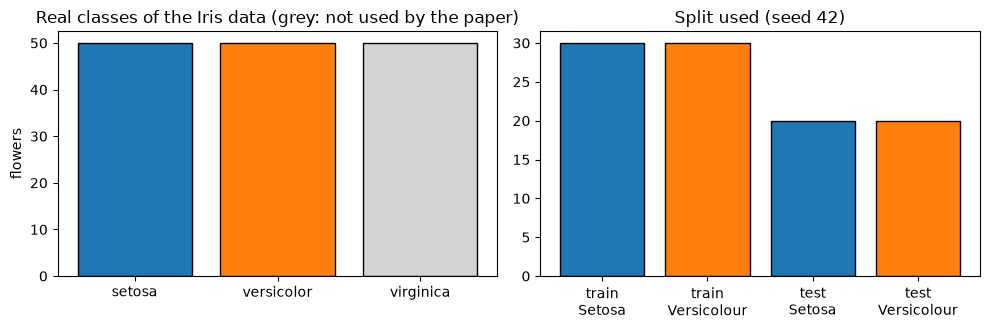

In [4]:
iris = load_iris()
X_all, y_all = iris.data, iris.target
species = list(iris.target_names)
print("Original Iris data:", X_all.shape, "| original label values:", dict(zip(species, np.bincount(y_all))))
print("Feature names:", iris.feature_names)
print(pd.DataFrame(X_all, columns=iris.feature_names).assign(species=[species[i] for i in y_all]).groupby("species").mean().round(2))

def make_split(seed):
    # Setosa (0) vs Versicolour (1); the 4th feature is set to 0 (= dropped), then l2 normalisation of every example (Du et al.)
    m = y_all < 2
    X3 = X_all[m][:, :3]
    y = y_all[m]
    Xn = X3 / np.linalg.norm(X3, axis=1, keepdims=True)
    Xtr, Xte, ytr, yte = train_test_split(Xn, y, test_size=N_TEST, stratify=y, random_state=seed)
    return Xtr, ytr, Xte, yte

def pad4(X):                      # amplitude vector on 2 qubits: 3 features + one zero amplitude
    X = np.atleast_2d(X)
    A = np.zeros((len(X), 4)); A[:, :3] = X
    return A

Xtr0, ytr0, Xte0, yte0 = make_split(SEED)
print(f"Used for the model: Setosa vs Versicolour, input dimension 3 -> train {Xtr0.shape}, test {Xte0.shape}")
print("train class counts:", dict(zip(species[:2], np.bincount(ytr0))), "| test:", dict(zip(species[:2], np.bincount(yte0))))
print("every input has unit l2 norm:", np.allclose(np.linalg.norm(Xtr0, axis=1), 1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
cnt = np.bincount(y_all)
ax[0].bar(species, cnt, color=["tab:blue", "tab:orange", "lightgrey"], edgecolor="k")
ax[0].set_title("Real classes of the Iris data (grey: not used by the paper)"); ax[0].set_ylabel("flowers")
ax[1].bar(["train\nSetosa", "train\nVersicolour", "test\nSetosa", "test\nVersicolour"],
          list(np.bincount(ytr0)) + list(np.bincount(yte0)), color=["tab:blue", "tab:orange"] * 2, edgecolor="k")
ax[1].set_title(f"Split used (seed {SEED})")
plt.tight_layout(); plt.show()

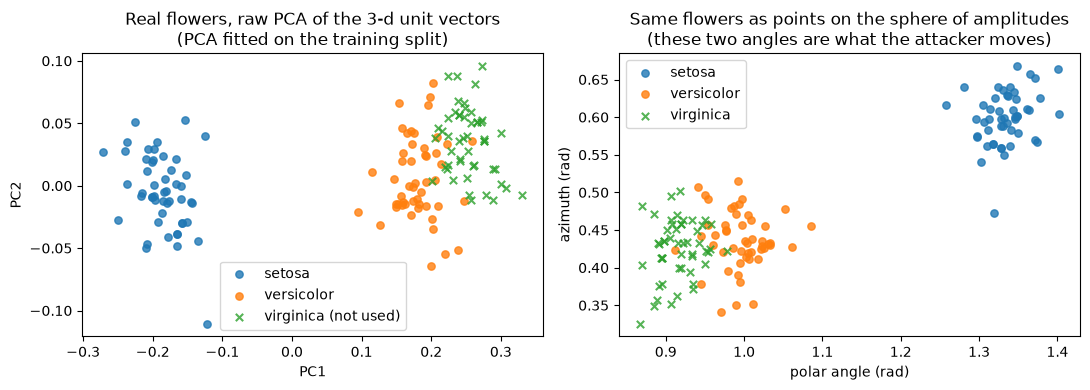

Setosa and Versicolour all have positive measurements, so after l2 normalisation they occupy a small cap of the sphere:
largest angle between any two used flowers (rad): 0.536


In [5]:
# 2-D scatter of real flowers coloured by ground-truth species. PCA is fitted on the training split only.
Xn_all = X_all[:, :3] / np.linalg.norm(X_all[:, :3], axis=1, keepdims=True)
pca = PCA(n_components=2, random_state=SEED).fit(Xtr0)
cols = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c in range(3):
    mk = "o" if c < 2 else "x"
    Z = pca.transform(Xn_all[y_all == c])
    ax[0].scatter(Z[:, 0], Z[:, 1], c=cols[c], marker=mk, s=28, alpha=.8, label=species[c] + ("" if c < 2 else " (not used)"))
ax[0].set_title("Real flowers, raw PCA of the 3-d unit vectors\n(PCA fitted on the training split)")
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend()
# amplitude encoding stores the unit vector as a quantum state: its direction (two angles) is all the classifier sees
def sph(X):
    return np.arccos(np.clip(X[:, 2], -1, 1)), np.arctan2(X[:, 1], X[:, 0])
for c in range(3):
    th, ph = sph(Xn_all[y_all == c])
    ax[1].scatter(th, ph, c=cols[c], marker="o" if c < 2 else "x", s=28, alpha=.8, label=species[c])
ax[1].set_title("Same flowers as points on the sphere of amplitudes\n(these two angles are what the attacker moves)")
ax[1].set_xlabel("polar angle (rad)"); ax[1].set_ylabel("azimuth (rad)"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Setosa and Versicolour all have positive measurements, so after l2 normalisation they occupy a small cap of the sphere:")
print("largest angle between any two used flowers (rad):",
      round(float(np.arccos(np.clip((Xn_all[y_all < 2] @ Xn_all[y_all < 2].T).min(), -1, 1))), 3))

## 1. The quantum model: exact simulator, real circuit, and the checks that tie them together

The classifier is the two-qubit circuit of the paper: amplitude encoding of the 3-d unit vector, five trainable layers, and a
measurement of qubit 0. Because everything is a 4x4 matrix we simulate it exactly with `numpy`: the class-0 probability is the quadratic
form `y0(x) = x^T M x` with `M = Re(U^dagger P0 U)` (`P0` projects qubit 0 on `|0>`). Training and the attacks need thousands of
evaluations, so the numpy version is used for speed; **every use of it is tied to the real Qiskit circuit** by the assertions in the next
cell: the trainable unitary equals Qiskit's `Operator`, the full circuit's `Statevector` gives the same `y0`, and the depolarised
density matrix produced by the Qiskit-Aer density-matrix simulator equals `p I/4 + (1-p)|psi><psi|`, for channels inserted at five
different places (this is the paper's Eq. (10) and the statement that the placement does not matter).


In [6]:
# ---------- the classifier: exact simulator written with numpy (asserted equal to the real Qiskit circuit below) ----------
NP = 5 * N_LAYERS                                   # trainable angles: per layer RZ RY RZ on qubit 0, RY RZ on qubit 1  (CHOICE)

def rzb(t):
    o = np.zeros(t.shape + (2, 2), complex); o[..., 0, 0] = np.exp(-1j * t / 2); o[..., 1, 1] = np.exp(1j * t / 2); return o
def ryb(t):
    c, s = np.cos(t / 2), np.sin(t / 2)
    o = np.zeros(t.shape + (2, 2), complex); o[..., 0, 0] = c; o[..., 0, 1] = -s; o[..., 1, 0] = s; o[..., 1, 1] = c; return o
CX01 = np.array([[1, 0, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0], [0, 1, 0, 0]], dtype=complex)   # control qubit 0, target qubit 1 (Qiskit order)
P0 = np.kron(np.eye(2), np.diag([1, 0]))                                                    # projector on "qubit 0 = |0>" (class 0)

def U_batch(TH):
    """unitary U(theta) of the trainable part for a batch of parameter vectors, shape (B, 4, 4)"""
    TH = np.atleast_2d(TH); B = len(TH)
    U = np.broadcast_to(np.eye(4, dtype=complex), (B, 4, 4)).copy()
    for l in range(N_LAYERS):
        a, b, c, d, e = [TH[:, 5 * l + k] for k in range(5)]
        g0 = rzb(c) @ ryb(b) @ rzb(a)                       # qubit 0: RZ(a) then RY(b) then RZ(c)
        g1 = rzb(e) @ ryb(d)                                # qubit 1: RY(d) then RZ(e)
        K = np.einsum("bij,bkl->bikjl", g1, g0).reshape(B, 4, 4)   # kron(g1, g0): qubit 1 is the most significant bit
        U = CX01 @ (K @ U)
    return U

def M_batch(TH):
    """effective measurement operator M = U^dagger P0 U (real part is enough for real amplitudes); y0(x) = x^T M x"""
    U = U_batch(TH)
    return np.real(np.conj(np.swapaxes(U, 1, 2)) @ P0 @ U)

def y0_of(M, A):                                    # ideal (noiseless, infinite-shot) probability of class 0
    return np.einsum("...i,ij,...j->...", A, M, A)

def noisy(y, p):                                    # paper Eq. (10)/(16) for K = 2
    return p / 2 + (1 - p) * y

# ---------- the real Qiskit circuit that this simulator stands for ----------
def add_layer(qc, th, l):
    a, b, c, d, e = th[5 * l:5 * l + 5]
    qc.rz(a, 0); qc.ry(b, 0); qc.rz(c, 0)               # qubit 0: single-qubit rotations
    qc.ry(d, 1); qc.rz(e, 1)                            # qubit 1: single-qubit rotations
    qc.cx(0, 1)                                         # fixed two-qubit gate (entanglement)

def build_circuit(x4, th, channels=None, measure=False):
    """Executed circuit: amplitude encoding of x4, N_LAYERS trainable layers, optional depolarising channels
    channels = {position: p}; position -1 = right after the state preparation, l = right after layer l."""
    qc = QuantumCircuit(2, 1 if measure else 0)
    qc.append(StatePreparation(x4), [0, 1])
    def chan(pos):
        if channels and pos in channels:
            qc.append(depolarizing_error(channels[pos], 2).to_instruction(), [0, 1])
    chan(-1)
    for l in range(N_LAYERS):
        add_layer(qc, th, l); chan(l)
    if measure:
        qc.measure(0, 0)
    return qc

In [7]:
# ---------- equivalence checks: numpy simulator == Qiskit circuit; exact channel == Qiskit-Aer density-matrix simulator ----------
rng = np.random.default_rng(SEED)
# (1) trainable unitary: numpy versus Qiskit Operator, 20 random parameter vectors
errs = []
for _ in range(20):
    th = rng.uniform(-np.pi, np.pi, NP)
    qcU = QuantumCircuit(2)
    for l in range(N_LAYERS):
        add_layer(qcU, th, l)
    errs.append(np.abs(Operator(qcU).data - U_batch(th)[0]).max())
assert max(errs) < 1e-12, max(errs)
print(f"(1) trainable unitary: numpy == Qiskit Operator, max abs error {max(errs):.1e} over 20 random parameter sets")

# (2) full circuit with amplitude encoding: probability of qubit 0 = |0> against x^T M x
errs = []
for i in range(10):
    th = rng.uniform(-np.pi, np.pi, NP); x = Xte0[i]
    sv = Statevector(build_circuit(pad4(x)[0], th))
    errs.append(abs(sv.probabilities([0])[0] - y0_of(M_batch(th)[0], pad4(x)[0])))
assert max(errs) < 1e-12, max(errs)
print(f"(2) y0 from Statevector of the full circuit == x^T M x, max abs error {max(errs):.1e}")

# (3) depolarising channel: Qiskit-Aer density-matrix simulation with several channels at different places
sim = AerSimulator(method="density_matrix", seed_simulator=SEED)
th_chk = rng.uniform(-np.pi, np.pi, NP); x_chk = pad4(Xte0[0])[0]
psi = Statevector(build_circuit(x_chk, th_chk)).data
def aer_rho(channels):
    qc = build_circuit(x_chk, th_chk, channels); qc.save_density_matrix()
    return np.array(sim.run(transpile(qc, sim)).result().data()["density_matrix"])
worst = 0
for ch in [{-1: 0.10, 1: 0.25, 4: 0.30}, {4: 1 - 0.9 * 0.75 * 0.7}, {0: 0.30, 2: 0.25, 3: 0.10}, {2: 0.5}, {}]:
    p_comb = 1 - np.prod([1 - q for q in ch.values()])
    rho_formula = p_comb * np.eye(4) / 4 + (1 - p_comb) * np.outer(psi, psi.conj())      # N_p(sigma) = p I/D + (1-p) sigma, Eq. (8)
    rho = aer_rho(ch)
    worst = max(worst, np.abs(rho - rho_formula).max())
    y0_noisy = np.real(np.trace(P0 @ rho))
    assert abs(y0_noisy - noisy(y0_of(M_batch(th_chk)[0], x_chk), p_comb)) < 1e-10      # Eq. (10): y~ = p/K + (1-p) y
assert worst < 1e-10, worst
print(f"(3) Aer density-matrix state with channels at 5 different placements == p I/4 + (1-p) |psi><psi| with p = 1 - prod(1-p_i); "
      f"max abs error {worst:.1e}.  Eq. (10) y~ = p/2 + (1-p) y holds and does not depend on where the channels sit.")
RES["eq10_err"] = float(worst)

(1) trainable unitary: numpy == Qiskit Operator, max abs error 4.8e-16 over 20 random parameter sets


(2) y0 from Statevector of the full circuit == x^T M x, max abs error 6.7e-16


(3) Aer density-matrix state with channels at 5 different placements == p I/4 + (1-p) |psi><psi| with p = 1 - prod(1-p_i); max abs error 8.9e-16.  Eq. (10) y~ = p/2 + (1-p) y holds and does not depend on where the channels sit.


## Quantum Circuit Architecture

The two drawings below show the circuit that is actually executed (and simulated by the exact numpy model above, which is
asserted equal to it): amplitude encoding of one flower, five trainable layers, the optional depolarising channel `N_p` on both
qubits, and the measurement of qubit 0. The circuit is drawn in elementary gates (`RZ`, `RY`, `CX`, plus the `U` gates that the state-preparation block decomposes into; the assertion in the code cell checks
that this decomposed circuit equals the executed one). Assumptions where the paper is silent: the exact gate pattern of one layer
(Fig. 7 is not readable from the PDF text) is our choice (`RZ RY RZ` on qubit 0, `RY RZ` on qubit 1, CNOT 0 -> 1, 5 parameters per layer,
25 in total); the channel is shown at the end of the circuit, but by Eq. (10) its position is irrelevant.


noiseless classifier (as trained)
   qubits: 2 | depth: 24 | gate counts: {'rz': 15, 'ry': 10, 'cx': 6, 'u': 3, 'measure': 1} | trainable parameters: 25 (the rotation angles of the 5 layers; the amplitude encoding and the channel have none)


classifier with one depolarising channel N_p (p = 0.5) before the measurement
   qubits: 2 | depth: 25 | gate counts: {'rz': 15, 'ry': 10, 'cx': 6, 'u': 3, 'quantum_channel': 1, 'measure': 1} | trainable parameters: 25 (the rotation angles of the 5 layers; the amplitude encoding and the channel have none)


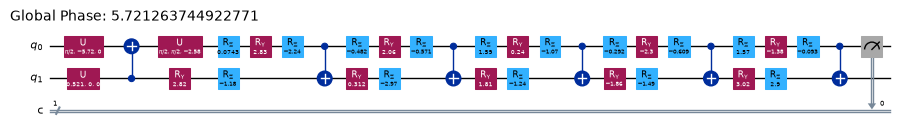

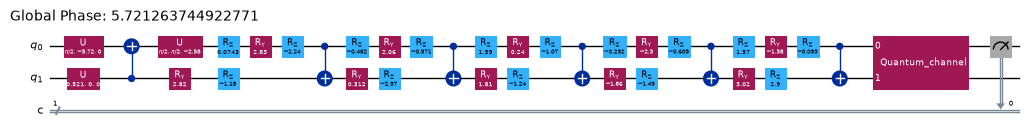

Reading the drawing: first the amplitude encoding of one Iris flower (the U gates and the CNOT at the left), then 5 layers of [RZ RY RZ on qubit 0 | RY RZ on qubit 1 | CNOT(0->1)]
(the 25 parameterised rotations after the encoding), then in the second drawing the depolarising channel N_p on both qubits, and finally the measurement of qubit 0 (class 0 = outcome 0).


In [8]:
from IPython.display import display
th_draw =np.random.default_rng(1).uniform(-np.pi, np.pi, NP)
x_draw = pad4(Xte0[0])[0]
# the executed circuit in elementary gates (the state preparation is decomposed into single-qubit rotations / U gates and a CNOT), equivalent to build_circuit
core = transpile(build_circuit(x_draw, th_draw), basis_gates=["rz", "ry", "cx", "u"], optimization_level=0)
assert Operator(core).equiv(Operator(build_circuit(x_draw, th_draw))), "decomposed drawing circuit differs from the executed circuit"
qc_clean = QuantumCircuit(2, 1); qc_clean.compose(core, inplace=True); qc_clean.measure(0, 0)
qc_noisy = QuantumCircuit(2, 1); qc_noisy.compose(core, inplace=True)
qc_noisy.append(depolarizing_error(0.5, 2).to_instruction(), [0, 1]); qc_noisy.measure(0, 0)
for name, qc in [("noiseless classifier (as trained)", qc_clean), ("classifier with one depolarising channel N_p (p = 0.5) before the measurement", qc_noisy)]:
    print(f"{name}\n   qubits: {qc.num_qubits} | depth: {qc.depth()} | gate counts: {dict(qc.count_ops())}"
          f" | trainable parameters: {NP} (the rotation angles of the 5 layers; the amplitude encoding and the channel have none)")
display(qc_clean.draw("mpl", fold=48, scale=0.5))
display(qc_noisy.draw("mpl", fold=48, scale=0.5))
print("Reading the drawing: first the amplitude encoding of one Iris flower (the U gates and the CNOT at the left), then 5 layers of [RZ RY RZ on qubit 0 | RY RZ on qubit 1 | CNOT(0->1)]")
print("(the 25 parameterised rotations after the encoding), then in the second drawing the depolarising channel N_p on both qubits, and finally the measurement of qubit 0 (class 0 = outcome 0).")

## 2. Training (the paper's Fig. 4) and classical baselines on identical inputs

We train as the paper describes: 60 training flowers, squared loss, learning rate 0.01, 50 epochs, one randomly drawn example per
update. The gradient is the exact parameter-shift gradient (every trainable gate is an `RZ` or `RY` rotation, so two shifted
evaluations give the exact derivative). Classical models are trained on exactly the same 3-d unit vectors and evaluated on the
same 40 test flowers. With 40 test flowers one flower is 2.5 accuracy points.


seed 42: final loss 0.104 | train acc 1.000 | test acc 1.000 | 38 s elapsed


seed 43: final loss 0.104 | train acc 1.000 | test acc 1.000 | 82 s elapsed


seed 44: final loss 0.102 | train acc 1.000 | test acc 1.000 | 124 s elapsed


seed 45: final loss 0.102 | train acc 1.000 | test acc 1.000 | 173 s elapsed


seed 46: final loss 0.103 | train acc 1.000 | test acc 1.000 | 211 s elapsed

Test accuracy on the same 40 flowers (same inputs for every model):
      QNN (ideal)  SVC rbf  SVC linear  RandomForest  LogReg
seed                                                        
42            1.0      1.0         1.0           1.0     1.0
43            1.0      1.0         1.0           1.0     1.0
44            1.0      1.0         1.0           1.0     1.0
45            1.0      1.0         1.0           1.0     1.0
46            1.0      1.0         1.0           1.0     1.0
      QNN (ideal)  SVC rbf  SVC linear  RandomForest  LogReg
mean          1.0      1.0         1.0           1.0     1.0
std           0.0      0.0         0.0           0.0     0.0


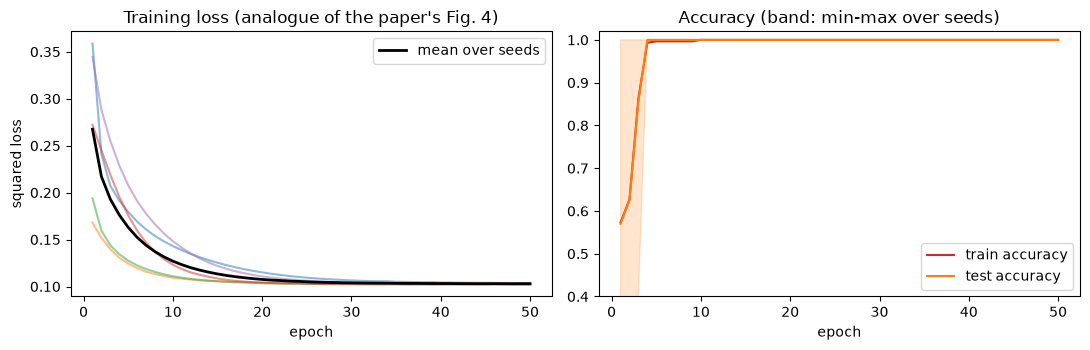

first epoch with 100 % test accuracy per seed: [4, 1, 2, 4, 4] | loss after epoch 30 (mean): 0.104 | final loss (mean): 0.103
ideal class-0 scores on the 40 test flowers: min 0.294, median 0.532, max 0.769


In [9]:
SH = np.vstack([np.eye(NP) * np.pi / 2, -np.eye(NP) * np.pi / 2])           # parameter-shift evaluations

def grad_y0(th, x):
    """exact gradient of y0(x; theta) by the parameter-shift rule (all gates are RZ/RY rotations)"""
    v = np.einsum("i,bij,j->b", x, M_batch(th[None, :] + SH), x)
    return 0.5 * (v[:NP] - v[NP:])

def train_model(Xtr, ytr, Xte, yte, seed, lr=LR, epochs=EPOCHS):
    # CHOICE: plain SGD on single randomly drawn examples, squared loss (c* - c_bar)^2 with c_bar = probability of class 1;
    # the paper's zeroth-order gradient is replaced by the exact parameter-shift gradient (same expectation).
    rng_ = np.random.default_rng(seed)
    th = rng_.uniform(0, 2 * np.pi, NP)
    A, B = pad4(Xtr), pad4(Xte)
    hist = []
    for ep in range(epochs):
        for i in rng_.permutation(len(A)):
            x = A[i]
            y0 = x @ M_batch(th)[0] @ x
            th = th - lr * 2 * (ytr[i] - (1 - y0)) * grad_y0(th, x)          # dL/dtheta = 2 (c* - y1) dy0/dtheta
        M = M_batch(th)[0]
        y0tr, y0te = y0_of(M, A), y0_of(M, B)
        hist.append((np.mean((ytr - (1 - y0tr)) ** 2), np.mean((y0tr < .5) == ytr), np.mean((y0te < .5) == yte)))
    return th, np.array(hist)

MODELS, HISTS, BASE = {}, {}, []
t0 = time.time()
for s in range(N_SEEDS):
    seed = SEED + s
    Xtr, ytr, Xte, yte = make_split(seed)
    th, h = train_model(Xtr, ytr, Xte, yte, seed)
    MODELS[seed], HISTS[seed] = th, h
    # classical baselines on exactly the same 3-d unit-vector inputs
    row = {"seed": seed, "QNN (ideal)": h[-1, 2]}
    for name, clf in [("SVC rbf", SVC(kernel="rbf", C=1.0)), ("SVC linear", SVC(kernel="linear", C=1.0)),
                      ("RandomForest", RandomForestClassifier(n_estimators=100, random_state=seed)),
                      ("LogReg", LogisticRegression(max_iter=1000))]:
        row[name] = clf.fit(Xtr, ytr).score(Xte, yte)
    BASE.append(row)
    print(f"seed {seed}: final loss {h[-1,0]:.3f} | train acc {h[-1,1]:.3f} | test acc {h[-1,2]:.3f} | {time.time()-t0:.0f} s elapsed")
base_df = pd.DataFrame(BASE).set_index("seed")
print("\nTest accuracy on the same 40 flowers (same inputs for every model):")
print(base_df.round(3).to_string()); print(base_df.agg(["mean", "std"]).round(3).to_string())

H = np.stack([HISTS[k] for k in HISTS])                                       # (seeds, epochs, 3)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ep = np.arange(1, EPOCHS + 1)
for k in HISTS:
    ax[0].plot(ep, HISTS[k][:, 0], alpha=.5)
ax[0].plot(ep, H[:, :, 0].mean(0), "k", lw=2, label="mean over seeds"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("squared loss"); ax[0].legend(); ax[0].set_title("Training loss (analogue of the paper's Fig. 4)")
ax[1].plot(ep, H[:, :, 1].mean(0), "tab:red", label="train accuracy"); ax[1].plot(ep, H[:, :, 2].mean(0), "tab:orange", label="test accuracy")
ax[1].fill_between(ep, H[:, :, 2].min(0), H[:, :, 2].max(0), color="tab:orange", alpha=.2); ax[1].set_ylim(.4, 1.02); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title("Accuracy (band: min-max over seeds)")
plt.tight_layout(); plt.show()
first100 = [int(np.argmax(HISTS[k][:, 2] >= 1.0)) + 1 if (HISTS[k][:, 2] >= 1.0).any() else None for k in HISTS]
print("first epoch with 100 % test accuracy per seed:", first100, "| loss after epoch 30 (mean):", round(float(H[:, 29, 0].mean()), 3), "| final loss (mean):", round(float(H[:, -1, 0].mean()), 3))
RES.update(first100=first100, loss30=float(H[:, 29, 0].mean()), loss_final=float(H[:, -1, 0].mean()),
           final_test=float(H[:, -1, 2].mean()), final_train=float(H[:, -1, 1].mean()), base=base_df.mean().to_dict())
TH_MAIN = MODELS[SEED]
M_MAIN = M_batch(TH_MAIN)[0]                   # the trained classifier, as a real 4x4 operator (enough for real amplitudes)
U_MAIN = U_batch(TH_MAIN)[0]; M_FULL = U_MAIN.conj().T @ P0 @ U_MAIN     # complex projector U^dagger P0 U: needed for unrestricted (complex, mixed) quantum adversaries
assert np.allclose(M_FULL.real, M_MAIN) and np.allclose(M_FULL @ M_FULL, M_FULL)
A3 = M_MAIN[:3, :3]                            # the same classifier restricted to the 3 feature amplitudes (4th amplitude = 0)
Xtr_m, ytr_m, Xte_m, yte_m = make_split(SEED)
Y0_TE = y0_of(M_MAIN, pad4(Xte_m))
print("ideal class-0 scores on the 40 test flowers: min %.3f, median %.3f, max %.3f" % (Y0_TE.min(), np.median(Y0_TE), Y0_TE.max()))

## 3. The closed forms: privacy budget, certified radius, the paper's worked example and Fig. 5

Corollary 1 says: if `B = y~_0 / y~_1 > exp(2 epsilon)` with `epsilon = ln(1 + 2 (1-p) tau_D / p)`, the label cannot change inside the
trace-distance ball of radius `tau_D`. Solving for `tau_D` gives the **certified radius**
`tau_cert = (sqrt(B~) - 1) p / (2 (1-p))` with `B~ = y~_c / (1 - y~_c)` and `y~_c = p/2 + (1-p) y_c` (Eq. 15). It is 0 at `p = 0` (no
noise, no certificate) and increases with `p`.

The numbers of the paper's worked example are pure arithmetic and can be checked at once. The paper names its column
"epsilon" with the values 1.04, 1.36 and 1.4; these are `exp(epsilon)`, as the table shows.


setting   p  tau_D  eps = ln(.)  exp(eps)  paper 'eps'  exp(2 eps)  paper exp(2 eps)  y~0 (clean)  paper y~0     B  paper B B > exp(2 eps)?
    (1) 0.5   0.02       0.0392      1.04         1.04       1.082              1.08       0.5446     0.5446 1.196     1.20             yes
    (2) 0.1   0.02       0.3075      1.36         1.36       1.850              1.85       0.5803     0.5804 1.383     1.38              no
    (3) 0.5   0.20       0.3365      1.40         1.40       1.960              1.96       0.5446     0.5446 1.196     1.20              no
-> the paper's column called 'eps' (1.04, 1.36, 1.4) is exp(eps): eps itself is 0.039, 0.307, 0.336. Everything else agrees to the printed digits.

example flower (test index 22, Setosa): ideal score y0 = 0.6506 (paper: 0.5892)
   p = 0: noisy score y~0 = 0.6506
   p = 0.5: noisy score y~0 = 0.5753
   p = 0.1: noisy score y~0 = 0.6356


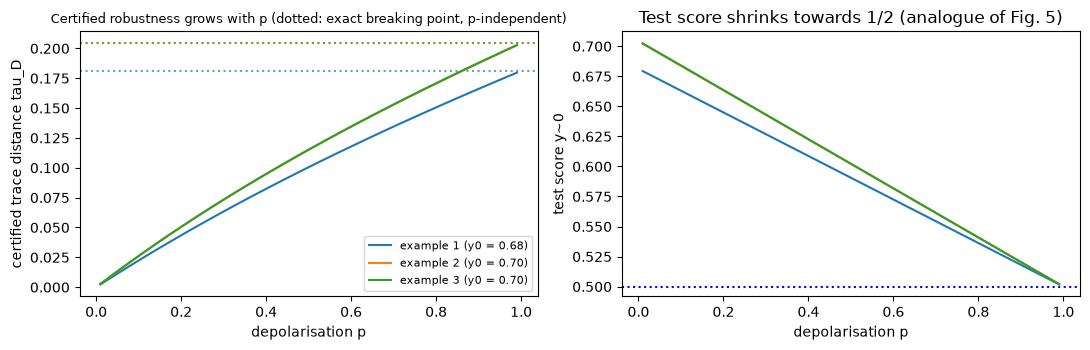

certified tau_D at p = 0.5 / 0.95 for the three examples: [(0.101, 0.174), (0.115, 0.196), (0.115, 0.196)]


In [10]:
# ---------- closed forms of the paper ----------
def eps_budget(p, tau, D=2):                    # Lemma 2, Eq. (11):  eps = ln(1 + Dmeas (1-p) tau / p)
    return np.log1p(D * (1 - p) * np.asarray(tau) / np.asarray(p))

def cert_tau(yc, p):
    """Largest trace distance certified by Corollary 1 for a binary classifier whose predicted class has ideal score yc > 1/2:
    B~ = y~_c / y~_other must exceed exp(2 eps)  <=>  tau < (sqrt(B~) - 1) p / (2 (1-p))   (Eq. 15 solved with Dmeas = 2)."""
    yt = noisy(np.asarray(yc, float), p)
    B = yt / (1 - yt)
    return (np.sqrt(B) - 1) * p / (2 * (1 - p))

def tau_star(yc):
    """Exact worst case (derived in the text below): the smallest trace distance at which an unrestricted quantum adversary can flip
    the label of a pure input state is (y_c - y_other)/2 = y_c - 1/2. It does not depend on p at all."""
    return np.asarray(yc, float) - 0.5

def tau_to_L(t):                                # l2 distance of two amplitude-encoded unit vectors whose states have trace distance t
    return np.sqrt(2 - 2 * np.sqrt(1 - np.minimum(t, 1.0) ** 2))

# ---- numbers of the paper's worked example (Section IV.C and Table I) that follow from closed forms alone ----
Y0_PAPER = 0.5892                               # clean ideal score of the paper's test example (Table I, p = 0, tau_D = 0)
paper_eps = {"(1)": (0.5, 0.02, 1.04, 1.08, 1.20, 0.5446), "(2)": (0.1, 0.02, 1.36, 1.85, 1.38, 0.5804), "(3)": (0.5, 0.2, 1.40, 1.96, 1.20, 0.5446)}
rows = []
for nm, (p, tau, e_paper, e2_paper, B_paper, y_paper) in paper_eps.items():
    e = float(eps_budget(p, tau)); yt0 = float(noisy(Y0_PAPER, p)); B = yt0 / (1 - yt0)
    rows.append([nm, p, tau, round(e, 4), round(math.exp(e), 3), e_paper, round(math.exp(2 * e), 3), e2_paper, round(yt0, 4), y_paper, round(B, 3), B_paper, "yes" if B > math.exp(2 * e) else "no"])
cf = pd.DataFrame(rows, columns=["setting", "p", "tau_D", "eps = ln(.)", "exp(eps)", "paper 'eps'", "exp(2 eps)", "paper exp(2 eps)", "y~0 (clean)", "paper y~0", "B", "paper B", "B > exp(2 eps)?"])
print(cf.to_string(index=False))
print("-> the paper's column called 'eps' (1.04, 1.36, 1.4) is exp(eps): eps itself is 0.039, 0.307, 0.336. Everything else agrees to the printed digits.")
RES["cf"] = cf

# ---- pick the test flower that plays the role of the paper's example: class 0 with ideal score closest to 0.5892 ----
cls0 = np.where(yte_m == 0)[0]
idx_ex = int(cls0[np.argmin(np.abs(Y0_TE[cls0] - Y0_PAPER))])
x_ex = Xte_m[idx_ex]
print(f"\nexample flower (test index {idx_ex}, Setosa): ideal score y0 = {Y0_TE[idx_ex]:.4f} (paper: {Y0_PAPER})")
for p in (0, 0.5, 0.1):
    print(f"   p = {p}: noisy score y~0 = {float(noisy(Y0_TE[idx_ex], p)):.4f}")

# ---- the paper's Fig. 5: certified tau_D and test score against p for three random test examples ----
rng5 = np.random.default_rng(SEED + 5)
picks = rng5.choice(np.where((yte_m == 0) & (Y0_TE > .5))[0], 3, replace=False)
p_grid = np.linspace(0.01, 0.99, 99)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for j, i in enumerate(picks):
    ax[0].plot(p_grid, cert_tau(Y0_TE[i], p_grid), label=f"example {j+1} (y0 = {Y0_TE[i]:.2f})")
    ax[1].plot(p_grid, noisy(Y0_TE[i], p_grid), label=f"example {j+1}")
    ax[0].axhline(tau_star(Y0_TE[i]), ls=":", color=f"C{j}", alpha=.7)
ax[0].set_xlabel("depolarisation p"); ax[0].set_ylabel("certified trace distance tau_D"); ax[0].set_title("Certified robustness grows with p (dotted: exact breaking point, p-independent)", fontsize=9)
ax[1].axhline(.5, color="b", ls=":"); ax[1].set_xlabel("depolarisation p"); ax[1].set_ylabel("test score y~0"); ax[1].set_title("Test score shrinks towards 1/2 (analogue of Fig. 5)")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print("certified tau_D at p = 0.5 / 0.95 for the three examples:", [(round(float(cert_tau(Y0_TE[i], .5)), 3), round(float(cert_tau(Y0_TE[i], .95)), 3)) for i in picks])

## 4. Checking Lemma 1, Proposition 1 and the differential-privacy bound of Lemma 2

* **Lemma 1** is tested on 20 000 random four-outcome circuits and on the trained binary classifier.
* **Proposition 1** is tested exactly: for each test flower and `p` we compute the probability (binomial, no sampling noise) that the
  majority of `N` shots equals the ideal label, at the paper's `N` and at the `N` that a two-sided Hoeffding bound requires.
* **Lemma 2** is tested on random pairs of density matrices `(sigma, rho)` (random rank, `rho = (1-t) sigma + t omega`), random unitaries
  and random `p`, with two measurements: the binary one (`Dmeas = 2`) and all four basis states (`Dmeas = 4`). We check
  `exp(-epsilon) <= y~_k(rho) / y~_k(sigma) <= exp(epsilon)` with the *actual* trace distance of each pair, and we construct the
  extremal pair for which the bound holds with equality.


In [11]:
rng4 = np.random.default_rng(SEED + 4)
# ---------- Lemma 1: noise never changes the winning class, K = 4 outcomes, random circuits ----------
def rand_unitaries(rng, n, D=4):
    Z = rng.normal(size=(n, D, D)) + 1j * rng.normal(size=(n, D, D))
    Q, R = np.linalg.qr(Z)
    d = np.diagonal(R, axis1=1, axis2=2); return Q * (d / np.abs(d))[:, None, :]
n1 = 20000
U = rand_unitaries(rng4, n1)
psi = rng4.normal(size=(n1, 4)) + 1j * rng4.normal(size=(n1, 4)); psi /= np.linalg.norm(psi, axis=1, keepdims=True)
yk = np.abs(np.einsum("nij,nj->ni", U, psi)) ** 2                 # computational-basis measurement, K = 4
pr = rng4.uniform(0, 1, n1)[:, None]
ykn = pr / 4 + (1 - pr) * yk                                       # Eq. (10) with K = 4
same_argmax = np.mean(yk.argmax(1) == ykn.argmax(1)); same_order = np.mean((np.argsort(yk, 1) == np.argsort(ykn, 1)).all(1))
print(f"Lemma 1 (K = 4, {n1} random circuits and states, random p): argmax identical in {100*same_argmax:.2f} % of cases, full ranking identical in {100*same_order:.2f} %")
bin_ok = all(((Y0_TE < .5) == (noisy(Y0_TE, p) < .5)).all() for p in np.linspace(0, 0.999, 50))
print("Lemma 1 for the trained binary classifier on the 40 test flowers, 50 values of p:", "labels unchanged" if bin_ok else "LABELS CHANGED")
RES.update(l1_argmax=float(same_argmax), l1_binary=bool(bin_ok))

# ---------- Proposition 1: shots needed so that the noisy label equals the ideal label with probability >= beta ----------
rows = []
for p in (0.2, 0.5, 0.8):
    for i in np.where((Y0_TE < .5) == yte_m)[0]:
        yc = max(Y0_TE[i], 1 - Y0_TE[i]); xi = 2 * yc - 1
        N_paper = int(np.ceil(np.log(2 / (1 - BETA_CONF)) / (8 * xi ** 2 * (1 - p) ** 2)))
        N_hoef = int(np.ceil(2 * np.log(2 / (1 - BETA_CONF)) / (xi ** 2 * (1 - p) ** 2)))      # rigorous two-sided Hoeffding for the binary case
        ytc = float(noisy(yc, p))
        P = lambda N: float(1 - binom.cdf(N // 2, N, ytc) + 0.5 * binom.pmf(N // 2, N, ytc) * (N % 2 == 0))   # P(majority = ideal label), tie = coin
        rows.append([p, xi, N_paper, P(max(N_paper, 1)), N_hoef, P(N_hoef)])
pr_df = pd.DataFrame(rows, columns=["p", "xi", "N (paper formula)", "P(label ok) at N_paper", "N (Hoeffding, 16x larger)", "P(label ok) at N_Hoeffding"])
g = pr_df.groupby("p").agg(frac_paper_ok=("P(label ok) at N_paper", lambda s: float((s >= BETA_CONF).mean())),
                           min_P_paper=("P(label ok) at N_paper", "min"), median_N_paper=("N (paper formula)", "median"),
                           frac_hoeffding_ok=("P(label ok) at N_Hoeffding", lambda s: float((s >= BETA_CONF).mean())), min_P_hoeff=("P(label ok) at N_Hoeffding", "min"))
print(f"\nProposition 1 (beta = {BETA_CONF}): fraction of test flowers whose label survives with probability >= beta at the paper's N, and at the rigorous N")
print(g.round(3).to_string())
print("The shots needed grow like 1/(xi (1-p))^2 as the paper says, but the paper's constant 1/8 is too small by a factor 16 for beta = 0.95 (see table).")
RES["prop1"] = g

# ---------- Lemma 2: the differential-privacy bound, tested on random neighbouring state pairs ----------
def rand_states(rng, n, D=4):
    r = rng.integers(1, D + 1, size=n)
    G = rng.normal(size=(n, D, D)) + 1j * rng.normal(size=(n, D, D))
    G = G * (np.arange(D)[None, :] < r[:, None])[:, None, :]
    rho = G @ np.conj(np.swapaxes(G, 1, 2)); tr = np.trace(rho, axis1=1, axis2=2).real
    return rho / tr[:, None, None]
def tdist(a, b): return 0.5 * np.abs(np.linalg.eigvalsh(a - b)).sum(-1)

n2 = DP_PAIRS
sig, om = rand_states(rng4, n2), rand_states(rng4, n2)
t = 10 ** rng4.uniform(-3, 0, n2)
rho = (1 - t)[:, None, None] * sig + t[:, None, None] * om
tau = tdist(rho, sig)
Ur = rand_unitaries(rng4, n2)
pp = rng4.uniform(0.02, 0.98, n2)
def probs(state, meas):
    S = Ur @ state @ np.conj(np.swapaxes(Ur, 1, 2))
    if meas == "binary":          # class 0 / class 1 = qubit 0 measured, rank-2 projectors, Dmeas = 2
        a = np.real(np.einsum("ij,nji->n", P0, S)); return np.stack([a, 1 - a], 1), 2
    return np.real(np.einsum("nii->ni", S)), 4          # all four basis states, rank-1 projectors, Dmeas = 4
dp_rows = []
for meas in ("binary", "basis4"):
    ys, D = probs(sig, meas); yr, _ = probs(rho, meas)
    K = ys.shape[1]; trace_pi = np.array([2, 2]) if meas == "binary" else np.ones(4)
    ys_n = pp[:, None] * trace_pi / 4 + (1 - pp[:, None]) * ys; yr_n = pp[:, None] * trace_pi / 4 + (1 - pp[:, None]) * yr
    eps = eps_budget(pp, tau, D)
    ratio = yr_n / ys_n
    ok = (ratio <= np.exp(eps)[:, None] * (1 + 1e-9)) & (ratio >= np.exp(-eps)[:, None] / (1 + 1e-9))
    tight = (np.maximum(ratio, 1 / ratio).max(1) - 1) / (np.exp(eps) - 1)
    dp_rows.append([meas, D, n2, int((~ok.all(1)).sum()), float(np.median(tight)), float(tight.max())])
dp_df = pd.DataFrame(dp_rows, columns=["measurement", "Dmeas", "pairs", "violations of e^-eps <= ratio <= e^eps", "median tightness", "max tightness"])
print("\nLemma 2 (quantum differential privacy of the depolarised classifier), random mixed/pure state pairs, random unitaries and p:")
print(dp_df.round(4).to_string(index=False))
# constructed extremal pair: sigma in the kernel of the class-0 projector, rho = (1-tau) sigma + tau |omega>, omega in its range  -> the bound is attained
e_sig = np.zeros(4); e_sig[1] = 1; e_om = np.zeros(4); e_om[0] = 1           # |q1 q0> = |01> and |00>
ext = []
for p in (0.1, 0.5, 0.9):
    for tau_ in (0.01, 0.1, 0.5):
        s_ = np.outer(e_sig, e_sig); r_ = (1 - tau_) * s_ + tau_ * np.outer(e_om, e_om)
        rat = (p / 2 + (1 - p) * np.trace(P0 @ r_)) / (p / 2 + (1 - p) * np.trace(P0 @ s_))
        ext.append(float(rat / np.exp(eps_budget(p, tau_))))
print("extremal pair: ratio / exp(eps) =", np.round(ext, 12), "-> the bound of Lemma 2 is attained, it cannot be improved")
assert dp_df.iloc[:, 3].sum() == 0 and np.allclose(ext, 1.0)
RES.update(dp=dp_df, ext_ratio=float(np.mean(ext)))

Lemma 1 (K = 4, 20000 random circuits and states, random p): argmax identical in 100.00 % of cases, full ranking identical in 100.00 %
Lemma 1 for the trained binary classifier on the 40 test flowers, 50 values of p: labels unchanged



Proposition 1 (beta = 0.95): fraction of test flowers whose label survives with probability >= beta at the paper's N, and at the rigorous N
     frac_paper_ok  min_P_paper  median_N_paper  frac_hoeffding_ok  min_P_hoeff
p                                                                              
0.2            0.0        0.747             6.0                1.0        0.997
0.5            0.0        0.750            15.0                1.0        0.997
0.8            0.0        0.751            88.5                1.0        0.997
The shots needed grow like 1/(xi (1-p))^2 as the paper says, but the paper's constant 1/8 is too small by a factor 16 for beta = 0.95 (see table).



Lemma 2 (quantum differential privacy of the depolarised classifier), random mixed/pure state pairs, random unitaries and p:
measurement  Dmeas  pairs  violations of e^-eps <= ratio <= e^eps  median tightness  max tightness
     binary      2  40000                                       0            0.1068         0.9506
     basis4      4  40000                                       0            0.1981         0.9225
extremal pair: ratio / exp(eps) = [1. 1. 1. 1. 1. 1. 1. 1. 1.] -> the bound of Lemma 2 is attained, it cannot be improved


## 5. The certified radius against explicit quantum adversaries, and the exact breaking point

**What an unrestricted quantum adversary can really do.** Take a pure input `sigma = |x><x|` and let `M_c` be the score operator of the true
class `c` (a rank-2 projector conjugated by `U`), with score `y_c = Tr(M_c sigma) > 1/2`. For any state `rho` at trace distance at most `tau`
write `rho - sigma = D+ - D-` (positive and negative part, `Tr D+ = Tr D- <= tau`). Because `0 <= M_c <= I`,
`Tr(M_c rho) >= y_c - Tr(D-) >= y_c - tau`. This is attained: write `|x> = a|e1> + b|e2>` with `|e1>` proportional to `M_c|x>` (inside the class-c subspace,
`a^2 = y_c`) and `|e2>` proportional to `(1 - M_c)|x>`; then `rho = sigma - tau|e1><e1| + tau|e2><e2|` is a quantum state whenever `tau <= a^2 - b^2 = 2 y_c - 1`
(the determinant of its 2x2 block), has trace distance exactly `tau` from `sigma`, and class-c score `y_c - tau`. Hence the label of the noiseless classifier can be flipped
if and only if `tau >= y_c - 1/2 = (y_c - y_other)/2`. With depolarising noise `y~_c - 1/2 = (1-p)(y_c - 1/2)`, so the noisy classifier is broken at the **same breaking
point `tau* = (y_c - y_other)/2`, which does not depend on `p`**. The certificate of the paper (Eq. 15) depends on `p`: it is 0 at `p = 0` and tends to `tau*` as `p -> 1`;
`tau_cert / tau*` measures how tight it is. We verify with explicit density matrices that no state inside the certified ball changes the label and that the label does flip
just beyond `tau*`, then compare with the strongest real attack on the amplitudes (exhaustive search). The cell also checks Theorem 4, the remark `tau >= l2`, and the
finite-shot certificate with a proper Hoeffding half-width.


clean accuracy of the trained circuit on the 40 test flowers: 1.0


   p  mean certified tau  median certified tau  mean exact breaking tau*  mean tightness (cert / exact)  mean certified l2 radius
0.20              0.0434                0.0433                    0.1797                         0.2401                    0.0434
0.50              0.1000                0.1003                    0.1797                         0.5547                    0.1002
0.80              0.1495                0.1502                    0.1797                         0.8310                    0.1499
0.95              0.1723                0.1733                    0.1797                         0.9587                    0.1730

explicit worst-case states (score y_c - tau) at 99.9999999 % of the certified distance: 0 label flips out of 160 (flowers x p); just above the exact breaking point: 160/160 flips;  random pure-state adversaries at the certified distance: 0 flips out of 3200

Theorem 4 radius vs the Corollary-1 radius: violations (Thm-4 radius larger than the exact


Finite-shot certificate (beta = 0.95) vs the infinite-shot one:
  p  shots N  fraction of flowers certified at tau >= 0.02  mean certified tau  frequency of over-claims (must be <= 0.05)
0.5       50                                        0.0448              0.0024                                      0.0018
0.5      500                                        0.6398              0.0329                                      0.0028
0.5     5000                                        0.9910              0.0765                                      0.0018
0.5    50000                                        1.0000              0.0925                                      0.0012
0.8       50                                        0.0128              0.0011                                      0.0022
0.8      500                                        0.1040              0.0069                                      0.0028
0.8     5000                                        0.8990              0.

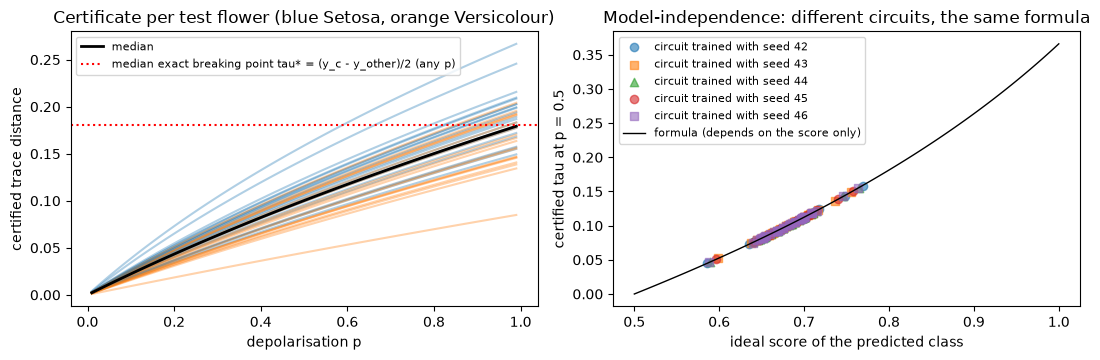

In [12]:
# ---------- the certified radius, explicit adversarial states, and the exact breaking point ----------
from scipy.linalg import null_space
CORRECT = (Y0_TE < .5) == yte_m
YC = np.maximum(Y0_TE, 1 - Y0_TE)                       # ideal score of the predicted class
print("clean accuracy of the trained circuit on the 40 test flowers:", CORRECT.mean())

def Mc_of(c): return M_FULL if c == 0 else np.eye(4) - M_FULL        # (complex) projector whose expectation is the score of class c
def adv_state(x4, tau, c):
    """Most damaging input state at trace distance tau <= 2 y_c - 1 from |x> (exact optimum, see text): with |e1> ~ M_c|x> (inside the
    class-c subspace) and |e2> ~ (1 - M_c)|x>,  rho = |x><x| - tau |e1><e1| + tau |e2><e2|  has trace distance tau and class-c score y_c - tau."""
    Mc = Mc_of(c); s = np.outer(x4, x4)
    e1 = Mc @ x4; e2 = x4 - e1
    e1 = e1 / np.linalg.norm(e1); e2 = e2 / np.linalg.norm(e2)
    return s - tau * np.outer(e1, e1.conj()) + tau * np.outer(e2, e2.conj()), s

def score_c(rho, c, p): return float(p / 2 + (1 - p) * np.real(np.trace(Mc_of(c) @ rho)))

rows, viol_cert, flip_above, n_chk = [], 0, 0, 0
rng_adv = np.random.default_rng(SEED + 6)
rand_viol = 0; n_rand = 0
for p in CERT_P:
    ct = cert_tau(YC, p); ts = tau_star(YC)
    for i in np.where(CORRECT)[0]:
        c = int(yte_m[i]); x4 = pad4(Xte_m[i])[0]
        rho_a, s = adv_state(x4, float(ct[i]) * (1 - 1e-9), c)
        assert abs(tdist(rho_a, s) - ct[i] * (1 - 1e-9)) < 1e-9 and np.linalg.eigvalsh(rho_a).min() > -1e-10
        viol_cert += score_c(rho_a, c, p) <= 0.5               # the label would flip inside the certified ball
        rho_b, _ = adv_state(x4, float(ts[i]) * 1.001, c)
        flip_above += score_c(rho_b, c, p) < 0.5               # just beyond the exact breaking point the label does flip
        n_chk += 1
        # random pure-state adversaries exactly at the certified trace distance
        for _ in range(20):
            v = rng_adv.normal(size=4) + 1j * rng_adv.normal(size=4); v -= np.vdot(x4, v) * x4; v /= np.linalg.norm(v)
            th_ = np.arcsin(min(float(ct[i]), 1.0)); psi_a = np.cos(th_) * x4 + np.sin(th_) * v
            rho_r = np.outer(psi_a, psi_a.conj())
            rand_viol += (p / 2 + (1 - p) * np.real(np.trace(Mc_of(c) @ rho_r))) <= 0.5; n_rand += 1
    rows.append([p, float(ct[CORRECT].mean()), float(np.median(ct[CORRECT])), float(ts[CORRECT].mean()), float((ct[CORRECT] / ts[CORRECT]).mean()),
                 float(tau_to_L(ct[CORRECT]).mean())])
cert_df = pd.DataFrame(rows, columns=["p", "mean certified tau", "median certified tau", "mean exact breaking tau*", "mean tightness (cert / exact)", "mean certified l2 radius"])
print(cert_df.round(4).to_string(index=False))
print(f"\nexplicit worst-case states (score y_c - tau) at 99.9999999 % of the certified distance: {viol_cert} label flips out of {n_chk} (flowers x p);"
      f" just above the exact breaking point: {flip_above}/{n_chk} flips;  random pure-state adversaries at the certified distance: {rand_viol} flips out of {n_rand}")
assert viol_cert == 0 and rand_viol == 0
RES.update(cert=cert_df, cert_viol=int(viol_cert + rand_viol), cert_checked=int(n_chk + n_rand), flip_above=int(flip_above), n_chk=int(n_chk))

# ---- Theorem 4 (kernel perceptron form) against the exact certificate ----
def thm4_radius(Bn, p):
    q = (1 - p) / p
    t1 = (Bn - 1) / (4 * (Bn + 1) + 8 * q)
    t2 = np.sqrt((Bn - 1) / (4 * q * (Bn + 1) + 8 * q ** 2))
    return np.where(q * t1 < 1, t1, t2)
Bn = YC / (1 - YC)
t4_viol = 0; t4_ratio = []
for p in CERT_P:
    t4 = thm4_radius(Bn, p); ex = cert_tau(YC, p)
    t4_viol += int((t4[CORRECT] > ex[CORRECT] * (1 + 1e-9)).sum()); t4_ratio.append(float((t4[CORRECT] / ex[CORRECT]).mean()))
print(f"\nTheorem 4 radius vs the Corollary-1 radius: violations (Thm-4 radius larger than the exact radius): {t4_viol}; mean ratio per p {np.round(t4_ratio, 3)}")
RES["thm4"] = (t4_viol, t4_ratio)

# ---- the paper's remark tau(sigma_x, sigma_x') >= l2 (Section V.A) ----
rng7 = np.random.default_rng(SEED + 7)
a = rng7.normal(size=(5000, 3)); b = a + rng7.normal(size=(5000, 3)) * rng7.uniform(0.05, 1.0, (5000, 1))
a = a / np.linalg.norm(a, axis=1, keepdims=True); b = b / np.linalg.norm(b, axis=1, keepdims=True)
l2 = np.linalg.norm(a - b, axis=1); trd = np.sqrt(1 - np.clip((a * b).sum(1), -1, 1) ** 2)
print(f"amplitude-encoded states: tau = l2 sqrt(1 - l2^2/4) <= l2 in {100*np.mean(trd <= l2 + 1e-12):.1f} % of 5000 random pairs (the paper writes sqrt(1 - l2^2/2) >= l2; "
      f"largest formula error {np.abs(trd - l2 * np.sqrt(1 - l2 ** 2 / 4)).max():.1e}). The consequence is harmless: an l2 ball of radius L is inside the trace-distance ball of radius L.")
RES["tau_vs_l2"] = float(np.mean(trd <= l2 + 1e-12))

# ---- finite-shot certificate (Theorem 2 / Corollary 2) with a proper Hoeffding half-width ----
def cert_tau_hat(k0, N, p, c, beta_=BETA_CONF):
    """k0 = observed number of outcome '0' in N runs; c = ideal label; returns certified tau (0 if none) valid with probability >= beta_"""
    zeta = math.sqrt(math.log(2 / (1 - beta_)) / (2 * N))
    yt0 = k0 / N; yc_hat = yt0 if c == 0 else 1 - yt0
    num, den = yc_hat - zeta, (1 - yc_hat) + zeta
    if num <= 0: return 0.0
    Bh = num / den
    return max((math.sqrt(Bh) - 1) * p / (2 * (1 - p)), 0.0) if Bh > 1 else 0.0
rng_n = np.random.default_rng(SEED + 8)
fs_rows = []
for p in (0.5, 0.8):
    for N in (50, 500, 5000, 50000):
        fracs, fails, taus = [], 0, []
        for i in np.where(CORRECT)[0]:
            c = int(yte_m[i]); yt0 = float(noisy(Y0_TE[i], p)); exact = float(cert_tau(YC[i], p))
            k0s = rng_n.binomial(N, yt0, size=MC_REPS)
            th_ = np.array([cert_tau_hat(k, N, p, c) for k in k0s])
            fracs.append(np.mean(th_ >= 0.02)); taus.append(th_.mean()); fails += int((th_ > exact * (1 + 1e-9)).sum())
        fs_rows.append([p, N, float(np.mean(fracs)), float(np.mean(taus)), fails / (MC_REPS * CORRECT.sum())])
fs_df = pd.DataFrame(fs_rows, columns=["p", "shots N", "fraction of flowers certified at tau >= 0.02", "mean certified tau", "frequency of over-claims (must be <= 0.05)"])
print("\nFinite-shot certificate (beta = 0.95) vs the infinite-shot one:")
print(fs_df.round(4).to_string(index=False))
RES["fs"] = fs_df

# ---- figure: certified radius against p, and against the margin for two different trained circuits ----
fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
for i in np.where(CORRECT)[0]:
    ax[0].plot(p_grid, cert_tau(YC[i], p_grid), color="tab:blue" if yte_m[i] == 0 else "tab:orange", alpha=.35)
ax[0].plot(p_grid, np.median([cert_tau(v, p_grid) for v in YC[CORRECT]], 0), "k", lw=2, label="median")
ax[0].axhline(np.median(tau_star(YC[CORRECT])), color="r", ls=":", label="median exact breaking point tau* = (y_c - y_other)/2 (any p)")
ax[0].set_xlabel("depolarisation p"); ax[0].set_ylabel("certified trace distance"); ax[0].legend(fontsize=8); ax[0].set_title("Certificate per test flower (blue Setosa, orange Versicolour)")
mk = ["o", "s", "^"]
for k, (sd, th_) in enumerate(MODELS.items()):
    Mk = M_batch(th_)[0]; yk_ = y0_of(Mk, pad4(Xte_m)); ykc = np.maximum(yk_, 1 - yk_)
    ax[1].scatter(ykc, cert_tau(ykc, 0.5), marker=mk[k % 3], alpha=.6, label=f"circuit trained with seed {sd}")
yy = np.linspace(.5, 1, 100); ax[1].plot(yy, cert_tau(yy, .5), "k-", lw=1, label="formula (depends on the score only)")
ax[1].set_xlabel("ideal score of the predicted class"); ax[1].set_ylabel("certified tau at p = 0.5"); ax[1].legend(fontsize=8)
ax[1].set_title("Model-independence: different circuits, the same formula")
plt.tight_layout(); plt.show()

## 6. Real attacks: Fig. 8, and a gradient-masking audit

The paper's attacker is iterative FGSM, `x' <- x' + (L/T) sign(grad_x loss)` with the `l2` bound `L`. With exact probabilities
the gradient of the noisy loss is the gradient of the noiseless one times the positive factor `(1-p)`, so the **sign is the same for
every `p`**: depolarisation cannot change the attack, only the finite-shot classifier it is run against. With a finite number of shots,
however, the attacker's *estimate* of the gradient becomes noisier as `p` grows (the signal shrinks like `1-p` while the shot noise stays),
so an attacker that estimates the gradient from shots will look less successful at large `p`. That is gradient masking, not robustness.
We therefore run five attackers:

1. **shot-based I-FGSM** (the paper's setting as far as it is specified): gradient by finite differences of the sampled loss, 300 shots;
2. **exact-gradient I-FGSM** (gradient of the exact noisy channel);
3. **EOT I-FGSM** (average of several shot-gradient estimates);
4. **margin PGD** with the exact gradient of the score margin, shrinking steps and restarts;
5. **exhaustive optimal attack** (grid search over the whole `l2` cap).

Each attacked flower is classified (a) with 300 shots per prediction, as in Fig. 8, and (b) from the exact scores (which cannot depend
on `p`, Lemma 1).


In [13]:
# ---------- attacks: all act on the 3 feature amplitudes (unit vectors); the classifier is the trained circuit ----------
def to_phi(L): return 2 * np.arcsin(np.minimum(np.asarray(L, float), 2.0) / 2)         # chord length L on the unit sphere -> angle
def normalise(X): return X / np.linalg.norm(X, axis=-1, keepdims=True)
def proj_cap(Xp, X, phimax):
    """projection of Xp onto the spherical cap {unit x': ||x' - x||_2 <= L} around X (exact l2 constraint of the paper)"""
    Xp = normalise(Xp); ph = np.broadcast_to(np.asarray(phimax, float), (len(X),))
    c = np.clip((Xp * X).sum(-1), -1, 1); ang = np.arccos(c)
    u = Xp - c[:, None] * X; un = np.linalg.norm(u, axis=-1, keepdims=True); u = np.where(un > 1e-12, u / np.maximum(un, 1e-12), 0.0)
    back = normalise(np.cos(ph)[:, None] * X + np.sin(ph)[:, None] * u)
    return np.where((ang > ph)[:, None], back, Xp)
def y0_3(X): return np.einsum("ni,ij,nj->n", X, A3, X)
def label_of(y0): return (np.asarray(y0) < 0.5).astype(int)

def grad_exact(X, c, p):                        # exact gradient of the squared loss (c* - y~1)^2 through the exact depolarised channel
    yt1 = noisy(1 - y0_3(X), p)
    return (2 * (yt1 - c) * (-(1 - p)))[:, None] * (2 * X @ A3)
def sample_yt1(X, p, rng, shots):               # estimate of y~1 from `shots` runs of the noisy circuit (each run returns 1 with probability y~1)
    return rng.binomial(shots, np.clip(noisy(1 - y0_3(normalise(X)), p), 0, 1)) / shots
def grad_shots(X, c, p, rng, shots, delta=FD_DELTA, draws=1):
    """what an attacker who only sees measurement outcomes can do: central finite differences of the sampled loss;
    draws > 1 averages several independent estimates (expectation over transformation, EOT)"""
    g = np.zeros_like(X)
    for _ in range(draws):
        for j in range(3):
            e = np.zeros(3); e[j] = delta
            g[:, j] += ((c - sample_yt1(X + e, p, rng, shots)) ** 2 - (c - sample_yt1(X - e, p, rng, shots)) ** 2) / (2 * delta)
    return g / draws

def ifgsm(X, c, p, L, steps, grad_fn, return_path=False):
    """iterative FGSM with an l2 bound, Eq. (17): x' <- x' + (L/T) sign(grad), then projection on the ball"""
    Xa = X.copy(); path = [Xa.copy()]
    if L <= 0: return (Xa, path) if return_path else Xa
    ph = to_phi(L)
    for _ in range(steps):
        Xa = proj_cap(Xa + (L / steps) * np.sign(grad_fn(Xa)), X, ph); path.append(Xa.copy())
    return (Xa, path) if return_path else Xa

def margin_of(X, c): return (1 - 2 * c) * (2 * y0_3(X) - 1)                 # y_c - y_other (exact, any p>0 only rescales it)
def margin_pgd(X, c, L, steps, rng, restarts=4):
    """strongest gradient attack: exact gradient of the margin, normalised steps along the sphere, shrinking step, random restarts"""
    if np.all(np.asarray(L) <= 0): return X.copy()
    ph = to_phi(L); best = X.copy(); bm = margin_of(X, c)
    for r in range(restarts + 1):
        Xa = X.copy() if r == 0 else proj_cap(X + 0.5 * np.asarray(L).reshape(-1, 1) * rng.normal(size=X.shape), X, ph)
        for t in range(steps):
            g = ((1 - 2 * c) * 4)[:, None] * (Xa @ A3); g = g - (g * Xa).sum(-1, keepdims=True) * Xa
            eta = np.broadcast_to(ph, (len(X),))[:, None] * (0.5 * (1 - t / steps) + 0.05)
            Xa = proj_cap(Xa - eta * g / np.maximum(np.linalg.norm(g, axis=-1, keepdims=True), 1e-12), X, ph)
            m = margin_of(Xa, c); upd = m < bm; best[upd] = Xa[upd]; bm = np.where(upd, m, bm)
    return best
def grid_attack(X, c, L, n_az=720, radii=(0.3, 0.6, 1.0)):
    """(numerically exact) optimal attack: exhaustive search over the cap around each flower (angle grid)"""
    n = len(X); ph = np.broadcast_to(to_phi(L), (n,)).astype(float)
    UV = [null_space(X[i][None, :]) for i in range(n)]; U_ = np.stack([b[:, 0] for b in UV]); V_ = np.stack([b[:, 1] for b in UV])
    az = np.linspace(0, 2 * np.pi, n_az, endpoint=False)
    best = X.copy(); bm = margin_of(X, c)
    for r in radii:
        phi = (r * ph)[:, None, None]
        cand = np.cos(phi) * X[:, None, :] + np.sin(phi) * (np.cos(az)[None, :, None] * U_[:, None, :] + np.sin(az)[None, :, None] * V_[:, None, :])
        m = (1 - 2 * c)[:, None] * (2 * np.einsum("nai,ij,naj->na", cand, A3, cand) - 1)
        j = m.argmin(1); mm = m[np.arange(n), j]; upd = mm < bm
        best[upd] = cand[np.arange(n), j][upd]; bm = np.where(upd, mm, bm)
    return best

def eval_adv(Xadv, y, p, rng, shots=SHOTS, reps=MC_REPS):
    """returns (accuracy with `shots` runs per prediction, accuracy of the exact scores).  Exact-score accuracy cannot depend on p (Lemma 1)."""
    y0 = y0_3(Xadv); acc_exact = float(np.mean(label_of(y0) == y))
    k0 = rng.binomial(shots, np.clip(noisy(y0, p), 0, 1), size=(reps, len(y)))
    pred = np.where(2 * k0 == shots, rng.integers(0, 2, k0.shape), (2 * k0 < shots).astype(int))
    return float(np.mean(pred == y[None, :])), acc_exact

# ---- sanity checks of the attack machinery ----
Xq, yq = Xte_m, yte_m
g_chk = grad_exact(Xq, yq, 0.5); eps_fd = 1e-6; num = np.zeros_like(Xq)
for j in range(3):
    e = np.zeros(3); e[j] = eps_fd
    num[:, j] = (((yq - noisy(1 - y0_3(Xq + e), .5)) ** 2) - ((yq - noisy(1 - y0_3(Xq - e), .5)) ** 2)) / (2 * eps_fd)
assert np.allclose(g_chk, num, atol=1e-6), np.abs(g_chk - num).max()
Xa_t = ifgsm(Xq, yq, .5, 0.3, 10, lambda Z: grad_exact(Z, yq, .5))
assert np.all(np.linalg.norm(Xa_t - Xq, axis=1) <= 0.3 + 1e-9) and np.allclose(np.linalg.norm(Xa_t, axis=1), 1)
print("exact input gradient == finite differences; attacks stay on the unit sphere inside the l2 ball of radius L (max distance %.4f for L = 0.3)" % np.linalg.norm(Xa_t - Xq, axis=1).max())
print("sanity: the numpy y0 of an attacked flower equals the Qiskit circuit on that input:",
      np.isclose(Statevector(build_circuit(pad4(Xa_t[0])[0], TH_MAIN)).probabilities([0])[0], y0_3(Xa_t)[0]))

exact input gradient == finite differences; attacks stay on the unit sphere inside the l2 ball of radius L (max distance 0.3000 for L = 0.3)
sanity: the numpy y0 of an attacked flower equals the Qiskit circuit on that input: True


attack grid done in 226 s
clean accuracy with 300 shots per prediction: {0.0: 1.0, 0.5: 0.996, 0.8: 0.892} | exact scores: 1.0


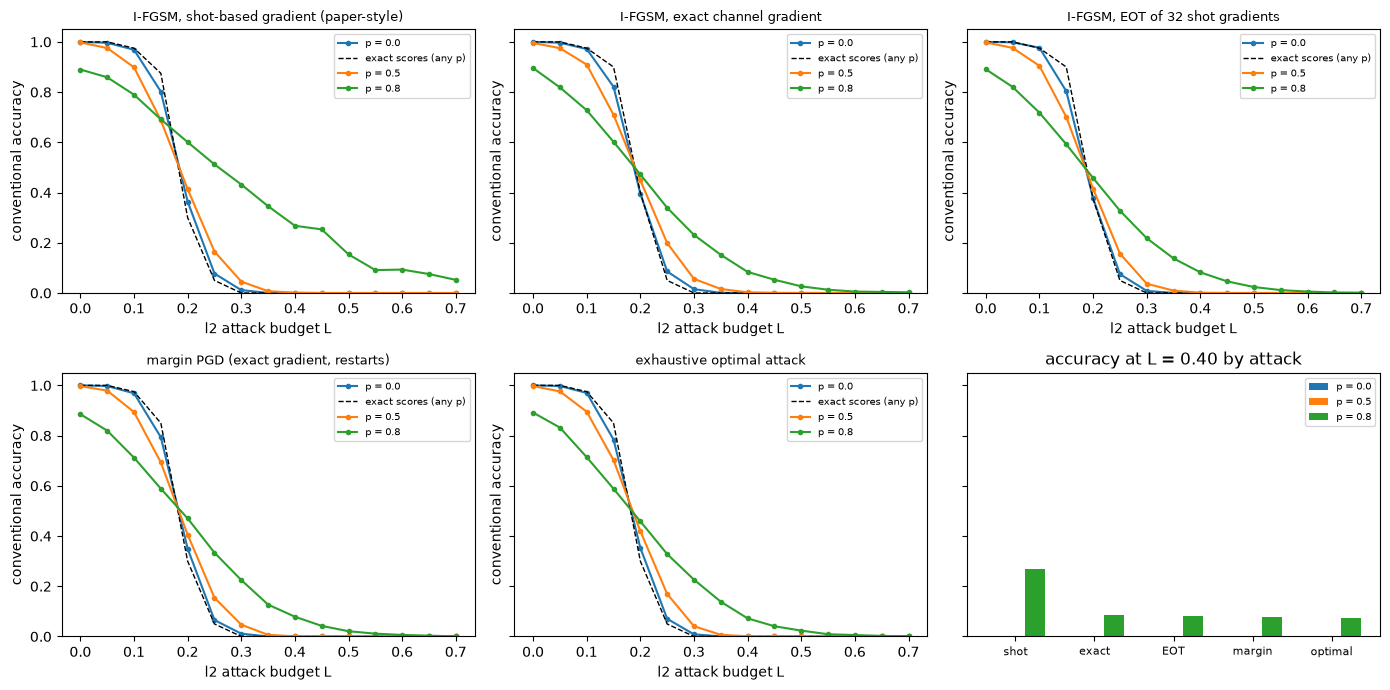

  L                                    attack  acc(p=0.0), 300 shots  acc(p=0.5), 300 shots  acc(p=0.8), 300 shots  exact acc, p=0  exact acc, p=0.8
0.1 I-FGSM, shot-based gradient (paper-style)                  0.969                  0.899                  0.790           0.975             1.000
0.1            I-FGSM, exact channel gradient                  0.972                  0.909                  0.728           0.975             0.975
0.1          I-FGSM, EOT of 32 shot gradients                  0.977                  0.904                  0.718           0.975             0.975
0.1     margin PGD (exact gradient, restarts)                  0.969                  0.894                  0.712           0.975             0.975
0.1                 exhaustive optimal attack                  0.970                  0.895                  0.714           0.975             0.975
0.2 I-FGSM, shot-based gradient (paper-style)                  0.364                  0.413               

cosine(shot-based gradient, exact gradient) for p = [0.0, 0.5, 0.8] -> [0.674 0.499 0.244] | with EOT: [0.683 0.734 0.644]



Certificate against the strongest attack found (smallest flipping budget per flower, exhaustive search):
   p  flowers broken INSIDE the certified ball  mean certified tau / tau reached by the best attack  mean certified L / smallest breaking L
0.20                                         0                                               0.2353                                  0.2343
0.50                                         0                                               0.5438                                  0.5421
0.80                                         0                                               0.8147                                  0.8135
0.95                                         0                                               0.9399                                  0.9394
exact breaking tau* (quantum adversary, any state) vs best real amplitude attack tau: ratio 0.98 (<= 1 as it must be: a real-amplitude attacker is a special case of the unrestricted quantum adve

In [14]:
# ---------- Fig. 8 analogue and the gradient-masking audit ----------
ATT_NAMES = ["I-FGSM, shot-based gradient (paper-style)", "I-FGSM, exact channel gradient", f"I-FGSM, EOT of {EOT_DRAWS} shot gradients", "margin PGD (exact gradient, restarts)", "exhaustive optimal attack"]
rngA = np.random.default_rng(SEED + 9)
ACC = {(a, p): [] for a in ATT_NAMES for p in P_LIST}          # accuracy with SHOTS runs per prediction
EXA = {(a, p): [] for a in ATT_NAMES for p in P_LIST}          # accuracy of the exact scores
ta = time.time()
for L in L_GRID:
    Xm = margin_pgd(Xq, yq, L, ATTACK_STEPS, rngA); Xo = grid_attack(Xq, yq, np.full(len(Xq), L)) if L > 0 else Xq.copy()
    for p in P_LIST:
        pp_ = max(p, 1e-9)
        advs = {ATT_NAMES[0]: ifgsm(Xq, yq, p, L, ATTACK_STEPS, lambda Z: grad_shots(Z, yq, p, rngA, SHOTS)),
                ATT_NAMES[1]: ifgsm(Xq, yq, p, L, ATTACK_STEPS, lambda Z: grad_exact(Z, yq, p)),
                ATT_NAMES[2]: ifgsm(Xq, yq, p, L, ATTACK_STEPS, lambda Z: grad_shots(Z, yq, p, rngA, SHOTS, draws=EOT_DRAWS)),
                ATT_NAMES[3]: Xm, ATT_NAMES[4]: Xo}
        for a, Xadv in advs.items():
            assert np.all(np.linalg.norm(Xadv - Xq, axis=1) <= L + 1e-7)
            s_, e_ = eval_adv(Xadv, yq, p, rngA); ACC[(a, p)].append(s_); EXA[(a, p)].append(e_)
print(f"attack grid done in {time.time()-ta:.0f} s")
# no-attack (L = 0) accuracy with SHOTS runs
clean_shots = {p: eval_adv(Xq, yq, p, rngA)[0] for p in P_LIST}
print("clean accuracy with %d shots per prediction:" % SHOTS, {p: round(v, 3) for p, v in clean_shots.items()}, "| exact scores:", float(np.mean(label_of(y0_3(Xq)) == yq)))

fig, axs = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for k, a in enumerate(ATT_NAMES):
    ax = axs.flat[k]
    for j, p in enumerate(P_LIST):
        ax.plot(L_GRID, ACC[(a, p)], "o-", ms=3, color=f"C{j}", label=f"p = {p}")
        if p == P_LIST[0]: ax.plot(L_GRID, EXA[(a, p)], "k--", lw=1, label="exact scores (any p)")
    ax.set_title(a, fontsize=9); ax.set_xlabel("l2 attack budget L"); ax.set_ylabel("conventional accuracy"); ax.legend(fontsize=7)
ax = axs.flat[5]
Lsel = int(np.argmin(np.abs(L_GRID - 0.4)))
w = 0.25
for j, p in enumerate(P_LIST):
    ax.bar(np.arange(len(ATT_NAMES)) + (j - 1) * w, [ACC[(a, p)][Lsel] for a in ATT_NAMES], w, label=f"p = {p}", color=f"C{j}")
ax.set_xticks(range(len(ATT_NAMES))); ax.set_xticklabels(["shot", "exact", "EOT", "margin", "optimal"], fontsize=8); ax.set_title(f"accuracy at L = {L_GRID[Lsel]:.2f} by attack"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# ---- the audit in numbers ----
rows = []
for L_t in (0.1, 0.2, 0.4, 0.5, 0.7):
    j = int(np.argmin(np.abs(L_GRID - L_t)))
    for a in ATT_NAMES:
        rows.append([round(float(L_GRID[j]), 3), a] + [round(ACC[(a, p)][j], 3) for p in P_LIST] + [round(EXA[(a, P_LIST[0])][j], 3), round(EXA[(a, P_LIST[-1])][j], 3)])
aud = pd.DataFrame(rows, columns=["L", "attack"] + [f"acc(p={p}), {SHOTS} shots" for p in P_LIST] + ["exact acc, p=0", f"exact acc, p={P_LIST[-1]}"])
print(aud.to_string(index=False))
RES["acc"] = {(a, p): list(v) for (a, p), v in ACC.items()}; RES["exa"] = {(a, p): list(v) for (a, p), v in EXA.items()}
ex_equal = all(np.allclose(EXA[(ATT_NAMES[1], P_LIST[0])], EXA[(ATT_NAMES[1], p)]) for p in P_LIST)
print("\nexact-gradient I-FGSM: accuracy of the exact scores identical for every p (noise only rescales the gradient):", ex_equal)
# gradient quality: cosine between the shot-based and the exact input gradient
cosr = []
for p in P_LIST:
    g_e = grad_exact(Xq, yq, p); g_s = grad_shots(Xq, yq, p, rngA, SHOTS)
    cosr.append(float(np.mean(np.sum(g_e * g_s, 1) / (np.linalg.norm(g_e, axis=1) * np.linalg.norm(g_s, axis=1) + 1e-12))))
cosr_eot = [float(np.mean(np.sum(grad_exact(Xq, yq, p) * grad_shots(Xq, yq, p, rngA, SHOTS, draws=EOT_DRAWS), 1) /
                          (np.linalg.norm(grad_exact(Xq, yq, p), axis=1) * np.linalg.norm(grad_shots(Xq, yq, p, rngA, SHOTS, draws=EOT_DRAWS), axis=1) + 1e-12))) for p in P_LIST]
print("cosine(shot-based gradient, exact gradient) for p =", P_LIST, "->", np.round(cosr, 3), "| with EOT:", np.round(cosr_eot, 3))
RES.update(cos_shot=cosr, cos_eot=cosr_eot, ex_equal=bool(ex_equal), clean_shots=clean_shots)

# ---- smallest attack that flips each flower (exact scores): tightness of the certificate against REAL attacks ----
lo, hi = np.zeros(len(Xq)), np.full(len(Xq), 1.5)
for _ in range(14):
    mid = (lo + hi) / 2; Xb = grid_attack(Xq, yq, mid, n_az=360)
    flipped = label_of(y0_3(Xb)) != yq; hi = np.where(flipped, mid, hi); lo = np.where(flipped, lo, mid)
L_flip = hi; tau_flip = np.sin(to_phi(L_flip))                 # trace distance reached by that attack (real amplitudes: sin of the angle)
tight_rows = []
for p in CERT_P:
    ct = cert_tau(YC, p)
    viol = int((tau_flip[CORRECT] < ct[CORRECT] * (1 - 1e-6)).sum())
    tight_rows.append([p, viol, float(np.mean(ct[CORRECT] / tau_flip[CORRECT])), float(np.mean(tau_to_L(ct[CORRECT]) / L_flip[CORRECT]))])
tight_df = pd.DataFrame(tight_rows, columns=["p", "flowers broken INSIDE the certified ball", "mean certified tau / tau reached by the best attack", "mean certified L / smallest breaking L"])
print("\nCertificate against the strongest attack found (smallest flipping budget per flower, exhaustive search):")
print(tight_df.round(4).to_string(index=False))
print("exact breaking tau* (quantum adversary, any state) vs best real amplitude attack tau: ratio", round(float(np.mean(tau_star(YC[CORRECT]) / tau_flip[CORRECT])), 3), "(<= 1 as it must be: a real-amplitude attacker is a special case of the unrestricted quantum adversary)")
assert tight_df.iloc[:, 1].sum() == 0
assert np.all(tau_flip[CORRECT] >= tau_star(YC[CORRECT]) - 2e-3), "an amplitude attack beat the exact quantum optimum"
RES.update(tight=tight_df, L_flip=L_flip, tau_flip=tau_flip)

## 6b. The paper's Table I and Fig. 6 on one test flower

Table I attacks one test flower for three settings `(p, tau_D)` with infinite shots and one setting with finite shots. We pick the
class-0 test flower whose ideal score is closest to the paper's 0.5892 and report the noisy score after the exact-gradient I-FGSM
and after the optimal attack, next to the paper's numbers. The finite-shot rows give the sampled score for one seeded draw, the exact
probability that the majority of the shots still says "class 0", and the Hoeffding-based certificate.


example flower: ideal class-0 score 0.6506 (paper's example 0.5892)


                  setting y~0 after exact-gradient I-FGSM y~0 after optimal attack paper's y~0 (Table I)     B exp(2 eps) certified?
         p = 0, no attack                65.06% (label 0)         65.06% (label 0)      58.92% (label 0) 1.862          -         no
(1) p = 0.5, tau_D = 0.02                56.60% (label 0)         56.57% (label 0)      52.96% (label 0) 1.355      1.082        yes
(2) p = 0.1, tau_D = 0.02                61.88% (label 0)         61.83% (label 0)      57.11% (label 0) 1.744       1.85         no
 (3) p = 0.5, tau_D = 0.2                47.94% (label 1)         47.66% (label 1)      49.42% (label 1) 1.355       1.96         no



finite-precision rows (p = 0.5, tau_D = 0.02):
 n_samp sampled y~0 of the attacked flower  paper (Table I)  P(majority label = 0)  Hoeffding zeta  B_hat = (y~0 - zeta)/(y~1 + zeta)  exp(2 eps) certified (95 %)?
     50                   54.00% (label 0) 44.32% (label 1)                  0.825          0.1921                              0.621       1.082                no
    500                   55.00% (label 0) 55.80% (label 0)                  0.998          0.0607                              1.060       1.082                no
   5000                   57.40% (label 0) 53.88% (label 0)                  1.000          0.0192                              1.253       1.082               yes
note: the paper's zeta = 0.95 would make (y~0 - zeta) negative; a Hoeffding half-width at 95 % confidence is the value printed above.


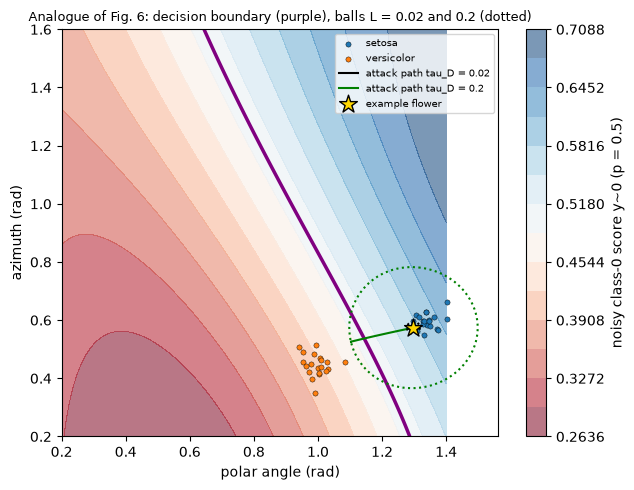

In [15]:
# ---------- analogue of the paper's Table I and Fig. 6 on the example flower ----------
xe = x_ex[None, :]; ce = np.array([0]); y0_clean = float(Y0_TE[idx_ex])
print(f"example flower: ideal class-0 score {y0_clean:.4f} (paper's example 0.5892)")
rngT = np.random.default_rng(SEED + 10)
settings = [("p = 0, no attack", 0.0, 0.0), ("(1) p = 0.5, tau_D = 0.02", 0.5, 0.02), ("(2) p = 0.1, tau_D = 0.02", 0.1, 0.02), ("(3) p = 0.5, tau_D = 0.2", 0.5, 0.2)]
paper_inf = {"p = 0, no attack": (58.92, 0), "(1) p = 0.5, tau_D = 0.02": (52.96, 0), "(2) p = 0.1, tau_D = 0.02": (57.11, 0), "(3) p = 0.5, tau_D = 0.2": (49.42, 1)}
rows, paths, t1num = [], {}, {}
for nm, p, L in settings:
    Xa, path = ifgsm(xe, ce, p, L, ATTACK_STEPS, lambda Z: grad_exact(Z, ce, p), return_path=True)
    Xo = grid_attack(xe, ce, np.array([L])) if L > 0 else xe
    yt_ifgsm, yt_opt = float(noisy(y0_3(Xa)[0], p)), float(noisy(y0_3(Xo)[0], p))
    ee = float(eps_budget(p, L)) if (p > 0 and L > 0) else 0.0
    Bn_ = float(noisy(y0_clean, p) / (1 - noisy(y0_clean, p)))
    cert_ok = (p > 0 and L > 0 and Bn_ > math.exp(2 * ee))
    rows.append([nm, f"{100*yt_ifgsm:.2f}% (label {int(yt_ifgsm < .5)})", f"{100*yt_opt:.2f}% (label {int(yt_opt < .5)})",
                 f"{paper_inf[nm][0]:.2f}% (label {paper_inf[nm][1]})", round(Bn_, 3), round(math.exp(2 * ee), 3) if ee else "-", "yes" if cert_ok else "no"])
    paths[nm] = path
    t1num[nm] = dict(clean=float(noisy(y0_clean, p)), ifgsm=yt_ifgsm, opt=yt_opt)
t1 = pd.DataFrame(rows, columns=["setting", "y~0 after exact-gradient I-FGSM", "y~0 after optimal attack", "paper's y~0 (Table I)", "B", "exp(2 eps)", "certified?"])
print(t1.to_string(index=False))
RES["t1"] = t1; RES["t1_vals"] = {r[0]: r for r in rows}; RES["t1num"] = t1num

# finite-precision part of Table I: p = 0.5, tau_D = 0.02, n_samp = 50 / 500 / 5000
rows = []
p_f, L_f = 0.5, 0.02
Xa_f = ifgsm(xe, ce, p_f, L_f, ATTACK_STEPS, lambda Z: grad_exact(Z, ce, p_f))
yt0_f = float(noisy(y0_3(Xa_f)[0], p_f)); ee = float(eps_budget(p_f, L_f))
paper_fin = {50: (44.32, 1), 500: (55.80, 0), 5000: (53.88, 0)}
for N in (50, 500, 5000):
    k0 = int(rngT.binomial(N, yt0_f)); est = k0 / N
    P_ok = float(1 - binom.cdf(N // 2, N, yt0_f) + 0.5 * binom.pmf(N // 2, N, yt0_f) * (N % 2 == 0))
    zeta = math.sqrt(math.log(2 / (1 - BETA_CONF)) / (2 * N)); Bh = (noisy(y0_clean, p_f) - zeta) / (1 - noisy(y0_clean, p_f) + zeta)
    rows.append([N, f"{100*est:.2f}% (label {int(est < .5)})", f"{paper_fin[N][0]:.2f}% (label {paper_fin[N][1]})", round(P_ok, 3), round(zeta, 4), round(Bh, 3), round(math.exp(2 * ee), 3), "yes" if Bh > math.exp(2 * ee) else "no"])
t1f = pd.DataFrame(rows, columns=["n_samp", "sampled y~0 of the attacked flower", "paper (Table I)", "P(majority label = 0)", "Hoeffding zeta", "B_hat = (y~0 - zeta)/(y~1 + zeta)", "exp(2 eps)", "certified (95 %)?"])
print("\nfinite-precision rows (p = 0.5, tau_D = 0.02):"); print(t1f.to_string(index=False))
print("note: the paper's zeta = 0.95 would make (y~0 - zeta) negative; a Hoeffding half-width at 95 % confidence is the value printed above.")
RES["t1f"] = t1f

# Fig. 6 analogue: the trained decision boundary in the angle plane, the flower, its certified balls and the attack paths
th_g = np.linspace(0.2, 1.4, 160); ph_g = np.linspace(0.2, 1.6, 160)
TT, PP = np.meshgrid(th_g, ph_g)
G3 = np.stack([np.sin(TT) * np.cos(PP), np.sin(TT) * np.sin(PP), np.cos(TT)], -1).reshape(-1, 3)
Z = noisy(y0_3(G3), 0.5).reshape(TT.shape)
fig, ax = plt.subplots(figsize=(6.5, 5))
cs = ax.contourf(TT, PP, Z, levels=np.linspace(Z.min(), Z.max(), 15), cmap="RdBu", alpha=.55); plt.colorbar(cs, label="noisy class-0 score y~0 (p = 0.5)")
ax.contour(TT, PP, Z, levels=[0.5], colors="purple", linewidths=2.5)
for c_, col in [(0, "tab:blue"), (1, "tab:orange")]:
    th_, ph_ = (np.arccos(Xte_m[yte_m == c_][:, 2]), np.arctan2(Xte_m[yte_m == c_][:, 1], Xte_m[yte_m == c_][:, 0]))
    ax.scatter(th_, ph_, c=col, s=14, edgecolor="k", linewidth=.3, label=species[c_])
for nm, col in [("(1) p = 0.5, tau_D = 0.02", "k"), ("(3) p = 0.5, tau_D = 0.2", "g")]:
    P_ = np.array(paths[nm]); ax.plot(np.arccos(P_[:, 0, 2]), np.arctan2(P_[:, 0, 1], P_[:, 0, 0]), "-", color=col, lw=1.5, label="attack path " + nm.split(",")[1].strip())
for L_, col in [(0.02, "k"), (0.2, "g")]:
    a_ = np.linspace(0, 2 * np.pi, 200); u_, v_ = null_space(x_ex[None, :]).T
    ring = np.cos(to_phi(L_)) * x_ex + np.sin(to_phi(L_)) * (np.cos(a_)[:, None] * u_ + np.sin(a_)[:, None] * v_)
    ax.plot(np.arccos(ring[:, 2]), np.arctan2(ring[:, 1], ring[:, 0]), ":", color=col)
ax.scatter([np.arccos(x_ex[2])], [np.arctan2(x_ex[1], x_ex[0])], marker="*", s=180, c="gold", edgecolor="k", zorder=5, label="example flower")
ax.set_xlabel("polar angle (rad)"); ax.set_ylabel("azimuth (rad)"); ax.set_title("Analogue of Fig. 6: decision boundary (purple), balls L = 0.02 and 0.2 (dotted)", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 7. Classical baseline: Gaussian randomised smoothing on the identical inputs

Randomised smoothing (Cohen, Rosenfeld and Kolter 2019) is the standard classical certificate: the smoothed classifier returns the
most likely class of `f(x + N(0, sigma^2 I))`; with a one-sided Clopper-Pearson lower bound `pA` on that probability its prediction is
constant inside an `l2` ball of radius `sigma Phi^-1(pA)`. We apply it to the same 40 test flowers (the same unit vectors, a logistic
regression trained on noise-augmented copies of the same 60 training flowers). For the quantum certificate the trace-distance radius is
converted to the largest `l2` distance of two amplitude vectors with that trace distance, `sqrt(2 - 2 sqrt(1 - tau^2))`, so that both are
radii in the same space. Certified accuracy at radius `r` = fraction of test flowers that are classified correctly *and* certified to at
least `r`. A flower counts as certified in the quantum case only when it is classified correctly; abstention does not exist there.
The quantum certificate is stronger in scope (it covers every quantum state, including mixed states and complex amplitudes), the
classical one only perturbations of the real vector.


plain logistic regression on the same inputs, test accuracy: 1.0


 sigma  smoothed accuracy  abstain fraction  median certified l2 radius (correct flowers)
  0.10                1.0               0.0                                         0.165
  0.25                1.0               0.0                                         0.157
  0.50                1.0               0.0                                         0.129


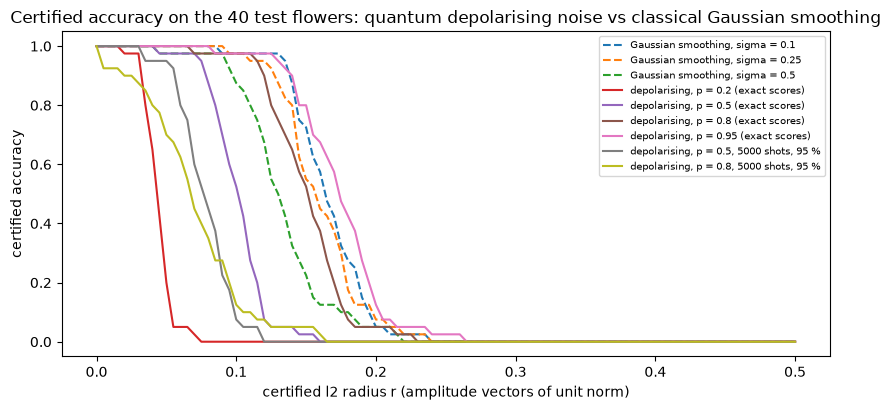

                                         r = 0.02  r = 0.05  r = 0.1  r = 0.2  r = 0.3
Gaussian smoothing, sigma = 0.1             1.000     1.000    0.975    0.050      0.0
Gaussian smoothing, sigma = 0.25            1.000     1.000    0.975    0.075      0.0
Gaussian smoothing, sigma = 0.5             1.000     0.975    0.875    0.050      0.0
depolarising, p = 0.2 (exact scores)        0.975     0.200    0.000    0.000      0.0
depolarising, p = 0.5 (exact scores)        1.000     0.975    0.525    0.000      0.0
depolarising, p = 0.8 (exact scores)        1.000     1.000    0.975    0.050      0.0
depolarising, p = 0.95 (exact scores)       1.000     1.000    0.975    0.125      0.0
depolarising, p = 0.5, 5000 shots, 95 %     1.000     0.950    0.075    0.000      0.0
depolarising, p = 0.8, 5000 shots, 95 %     0.900     0.700    0.125    0.000      0.0


In [16]:
# ---------- classical randomised smoothing (Cohen et al.) on exactly the same inputs ----------
RS_ALPHA = 0.001
def rs_fit(sigma, seed):
    # CHOICE: base classifier = logistic regression trained on Gaussian-noise-augmented copies (20 per flower) of the same 60 training flowers
    r_ = np.random.default_rng(seed)
    Xa = np.vstack([Xtr_m + r_.normal(scale=sigma, size=Xtr_m.shape) for _ in range(20)]); ya = np.tile(ytr_m, 20)
    return LogisticRegression(max_iter=3000, C=10.0).fit(Xa, ya)
def rs_certify(clf, X, sigma, n, rng):
    """prediction and certified l2 radius sigma * Phi^-1(pA_lower) of the smoothed classifier (binary case); abstains with radius -1"""
    out = []
    for x in X:
        k1 = int(clf.predict(x[None, :] + rng.normal(scale=sigma, size=(n, 3))).sum()); k0 = n - k1
        top = int(k1 > k0); kt = max(k0, k1)
        pA = beta_dist.ppf(RS_ALPHA, kt, n - kt + 1) if kt > 0 else 0.0           # one-sided Clopper-Pearson lower bound
        out.append((top, sigma * norm.ppf(pA) if pA > 0.5 else -1.0))
    return np.array(out)
rng_rs = np.random.default_rng(SEED + 11)
r_grid = np.linspace(0, 0.5, 101)
curves = {}
rs_rows = []
plain = LogisticRegression(max_iter=3000, C=10.0).fit(Xtr_m, ytr_m)
print("plain logistic regression on the same inputs, test accuracy:", plain.score(Xte_m, yte_m))
for sg in RS_SIGMAS:
    clf = rs_fit(sg, SEED); res_ = rs_certify(clf, Xte_m, sg, RS_N, rng_rs)
    ok = (res_[:, 0] == yte_m) & (res_[:, 1] >= 0)
    curves[f"Gaussian smoothing, sigma = {sg}"] = np.array([np.mean(ok & (res_[:, 1] >= r)) for r in r_grid])
    rs_rows.append([sg, float(np.mean(res_[:, 0] == yte_m)), float(np.mean(res_[:, 1] < 0)), float(np.median(res_[ok, 1])) if ok.any() else 0.0])
rs_df = pd.DataFrame(rs_rows, columns=["sigma", "smoothed accuracy", "abstain fraction", "median certified l2 radius (correct flowers)"])
print(rs_df.round(3).to_string(index=False))

# quantum certificates on the same flowers: infinite shots at several p, and a finite-shot certificate (N_CERT shots, 95 %)
for p in CERT_P:
    Lq = np.where(CORRECT, tau_to_L(cert_tau(YC, p)), -1.0)
    curves[f"depolarising, p = {p} (exact scores)"] = np.array([np.mean(CORRECT & (Lq >= r) ) for r in r_grid])
rng_q = np.random.default_rng(SEED + 12)
for p_fin in (0.5, 0.8):
    Lfin = np.array([tau_to_L(cert_tau_hat(int(rng_q.binomial(N_CERT, float(noisy(Y0_TE[i], p_fin)))), N_CERT, p_fin, int(yte_m[i]))) if CORRECT[i] else -1.0 for i in range(len(yte_m))])
    curves[f"depolarising, p = {p_fin}, {N_CERT} shots, 95 %"] = np.array([np.mean(CORRECT & (Lfin >= r)) for r in r_grid])
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for k, (nm, cv) in enumerate(curves.items()):
    ax.plot(r_grid, cv, "-" if nm.startswith("dep") else "--", label=nm)
ax.set_xlabel("certified l2 radius r (amplitude vectors of unit norm)"); ax.set_ylabel("certified accuracy"); ax.legend(fontsize=7); ax.set_title("Certified accuracy on the 40 test flowers: quantum depolarising noise vs classical Gaussian smoothing")
plt.tight_layout(); plt.show()
rad = [0.02, 0.05, 0.1, 0.2, 0.3]
ca = pd.DataFrame({nm: [float(cv[np.argmin(np.abs(r_grid - r))]) for r in rad] for nm, cv in curves.items()}, index=[f"r = {r}" for r in rad]).T
print(ca.round(3).to_string())
RES["rs"] = rs_df; RES["ca"] = ca

## 8. Paper versus this notebook

Every claim of the paper that can be tested here, with the paper's value, the notebook's value and a verdict. Tolerance for the
numeric comparison: 2 accuracy points or 0.02 on a probability; "reproduced" for a qualitative claim means that the stated pattern is
found. Where a claim is true for the certificate but false for the real attacker, two rows are given.


In [17]:
# ---------- the paper's claims next to this notebook's numbers, one verdict each (tolerance: 2 accuracy points / 0.02) ----------
jL = lambda L: int(np.argmin(np.abs(L_GRID - L)))
A0, A1, A3_, A4_, A5_ = ATT_NAMES
acc = RES["acc"]; exa = RES["exa"]
def verdict_num(paper, mine, tol):
    return "reproduced" if abs(paper - mine) <= tol else (f"exceeded (+{mine-paper:.3f})" if mine > paper else f"not reached ({mine-paper:+.3f})")
cf = RES["cf"]; t1v = RES["t1_vals"]; t1f = RES["t1f"]
rowsV = []
def add(claim, paper, mine, verdict): rowsV.append([claim, paper, mine, verdict])

add("Eq. (10): y~ = p/K + (1-p) y, independent of where the channels sit", "exact", f"Aer density matrix, 5 placements, max error {RES['eq10_err']:.1e}", "reproduced" if RES["eq10_err"] < 1e-10 else "not reached")
add("Lemma 1: depolarisation never changes the winning class", "always", f"K=4: argmax kept in {100*RES['l1_argmax']:.2f} % of 20000 random circuits; trained circuit: {'kept' if RES['l1_binary'] else 'CHANGED'}", "reproduced" if RES["l1_argmax"] == 1.0 and RES["l1_binary"] else "not reached")
g = RES["prop1"]
add("Proposition 1: N ~ ln(2/(1-beta)) / (8 xi^2 (1-p)^2) shots suffice", "label kept with prob >= 0.95", f"fraction of flowers meeting 0.95 at the paper's N: {np.round(g['frac_paper_ok'].values, 2)} (p = 0.2/0.5/0.8); at 16x N: {np.round(g['frac_hoeffding_ok'].values, 2)}",
    "reproduced" if (g["frac_paper_ok"] >= 0.99).all() else "scaling reproduced, constant not reached (needs 16x)")
add("Lemma 2: eps = ln(1 + Dmeas (1-p) tau_D / p) is a valid quantum-DP budget", "valid for all state pairs", f"violations: {int(RES['dp'].iloc[:, 3].sum())} in {int(RES['dp'].iloc[:, 2].sum())} random pair-measurements; extremal pair attains the bound (ratio {RES['ext_ratio']:.9f})", "reproduced" if RES["dp"].iloc[:, 3].sum() == 0 else "not reached")
d_e = max(abs(cf["exp(eps)"].values - cf["paper 'eps'"].values)); d_e2 = max(abs(cf["exp(2 eps)"].values - cf["paper exp(2 eps)"].values)); d_B = max(abs(cf["B"].values - cf["paper B"].values))
add("Sec. IV.C numbers: 'eps' = 1.04 / 1.36 / 1.4; e^(2 eps) = 1.08 / 1.85 / 1.96; B = 1.20 / 1.38 / 1.20", "see left", f"max deviation: exp(eps) {d_e:.3f}, exp(2 eps) {d_e2:.3f}, B {d_B:.3f} (the paper's 'eps' column is exp(eps))", "reproduced" if max(d_e, d_e2, d_B) <= 0.01 else "not reached")
d_y = max(abs(cf["y~0 (clean)"].values - cf["paper y~0"].values))
add("Table I: noisy scores 54.46 % (p=0.5) and 58.04 % (p=0.1) from the clean score 58.92 %", "54.46 / 58.04 %", f"{100*cf['y~0 (clean)'].values[0]:.2f} / {100*cf['y~0 (clean)'].values[1]:.2f} % (closed form); our example flower: {100*float(noisy(Y0_TE[idx_ex], 0.5)):.2f} / {100*float(noisy(Y0_TE[idx_ex], 0.1)):.2f} %", "reproduced" if d_y <= 0.0005 else verdict_num(0.5446, cf["y~0 (clean)"].values[0], 0.02))
# Table I attack rows: the example flower differs (clean score 0.65 here, 0.5892 in the paper), so the label outcome and the DROP of the noisy score are compared
def parse(s): return float(s.split("%")[0]) / 100, int(s.split("label ")[1].rstrip(")"))
pap_clean = {"(1) p = 0.5, tau_D = 0.02": 0.5446, "(2) p = 0.1, tau_D = 0.02": 0.5804, "(3) p = 0.5, tau_D = 0.2": 0.5446}
for nm in ("(1) p = 0.5, tau_D = 0.02", "(2) p = 0.1, tau_D = 0.02", "(3) p = 0.5, tau_D = 0.2"):
    r_ = t1v[nm]; pap, plab = parse(r_[3]); n_ = RES["t1num"][nm]
    lab = int(n_["ifgsm"] < .5); drop_m, drop_p = n_["clean"] - n_["ifgsm"], pap_clean[nm] - pap
    v = "reproduced" if (lab == plab and abs(drop_m - drop_p) <= 0.02) else (f"label reproduced; score drop differs ({100*drop_m:.1f} vs {100*drop_p:.1f} points)" if lab == plab else "not reached (label differs)")
    add(f"Table I attack row {nm}: label and drop of y~0 after the bounded attack", f"{r_[3]}; drop {100*drop_p:.1f} points", f"{r_[1]} (clean {100*n_['clean']:.2f} %); drop {100*drop_m:.1f} points; optimal attack {r_[2]}", v)
labs =[parse(s)[1] for s in t1f.iloc[:, 1]]
add("Table I finite precision (p=0.5, tau_D=0.02): labels after attack for n_samp = 50 / 500 / 5000", "1 / 0 / 0", f"{labs[0]} / {labs[1]} / {labs[2]} (one seeded draw; P(label 0) = {t1f.iloc[0,3]:.2f} / {t1f.iloc[1,3]:.2f} / {t1f.iloc[2,3]:.2f})", "reproduced" if labs == [1, 0, 0] else "not reached (single random draw)")
cert5000 = t1f.iloc[2, 7]; cert_small = (t1f.iloc[0, 7], t1f.iloc[1, 7])
add("Cor. 2: n_samp = 5000 certifies robustness (and 50, 500 do not)", "5000 yes; zeta = 0.95 (not usable as printed)", f"Hoeffding zeta at 95 %: 5000 -> {cert5000}; 50 -> {cert_small[0]}; 500 -> {cert_small[1]}", "reproduced" if (cert5000 == "yes" and cert_small == ("no", "no")) else "not reached")
add("Fig. 4: training and test accuracy reach 100 % after 15 epochs", "100 % by epoch 15 (about 5)", f"first epoch with 100 % test accuracy per seed: {RES['first100']}; final train {RES['final_train']:.3f}, test {RES['final_test']:.3f}", "reproduced" if all(f is not None and f <= 15 for f in RES["first100"]) and RES["final_test"] >= 0.98 else "not reached")
add("Fig. 4: loss decreases to about 0.14 (axis 0.14-0.26) at epoch 30", "about 0.14", f"epoch-30 loss {RES['loss30']:.3f}, final {RES['loss_final']:.3f}", verdict_num(0.14, RES["loss30"], 0.02))
# Fig. 8
a30 = lambda a, p, L: acc[(a, p)][jL(L)]; e30 = lambda a, p, L: exa[(a, p)][jL(L)]
for lab_, A_ in (("paper-style shot-gradient I-FGSM", A0), ("adaptive exact-gradient I-FGSM", A1), ("margin PGD", A4_), ("EOT I-FGSM", A3_)):
    z0 = a30(A_, 0.0, 0.4) <= 0.02; nz = a30(A_, 0.5, 0.4) > 0.02 and a30(A_, 0.8, 0.4) > 0.02
    add(f"Fig. 8 text, {lab_}: accuracy of baseline (p=0) is zero at L=0.4 while p=0.5 and p=0.8 stay non-zero", "p=0: 0; p=0.5/0.8: > 0",
        f"L=0.4 (acc with {SHOTS} shots): p=0 {a30(A_,0.0,0.4):.3f}, p=0.5 {a30(A_,0.5,0.4):.3f}, p=0.8 {a30(A_,0.8,0.4):.3f}", "reproduced" if (z0 and nz) else ("not reached: " + ("baseline is not zero" if not z0 else ", ".join(f"p={pq} is {a30(A_, pq, 0.4):.3f}" for pq in (0.5, 0.8) if a30(A_, pq, 0.4) <= 0.02) + " (about zero)")))
for lab_, A_ in (("paper-style shot-gradient I-FGSM", A0), ("adaptive exact-gradient I-FGSM", A1)):
    c_ = a30(A_, 0.0, 0.5) <= 0.02 and a30(A_, 0.5, 0.5) <= 0.02 and a30(A_, 0.8, 0.5) > 0.02
    add(f"Fig. 8 text, {lab_}: at L=0.5 baseline and p=0.5 are zero, p=0.8 is non-zero", "0 / 0 / > 0", f"L=0.5: p=0 {a30(A_,0.0,0.5):.3f}, p=0.5 {a30(A_,0.5,0.5):.3f}, p=0.8 {a30(A_,0.8,0.5):.3f}", "reproduced" if c_ else "not reached")
    c2 = a30(A_, 0.8, 0.1) <= a30(A_, 0.5, 0.1)
    add(f"Fig. 8 text, {lab_}: at L=0.1 accuracy(p=0.8) is slightly below accuracy(p=0.5)", "acc(0.8) < acc(0.5)", f"L=0.1: p=0.5 {a30(A_,0.5,0.1):.3f}, p=0.8 {a30(A_,0.8,0.1):.3f}", "reproduced" if c2 else "not reached")
    c3 = all(a30(A_, 0.8, L) >= a30(A_, 0.5, L) - 0.02 and a30(A_, 0.5, L) >= a30(A_, 0.0, L) - 0.02 for L in L_GRID[L_GRID >= 0.3])
    add(f"Fig. 8 text, {lab_}: larger p gives higher accuracy at large L (L >= 0.3)", "monotone in p", "see the figure and the audit table above",
        ("reproduced" + (" (gradient masking and shot noise)" if A_ == A0 else " (through shot noise only: exact-score accuracy is identical for every p)" if RES["ex_equal"] else "")) if c3 else "not reached")
add("Robustness from noise is real, i.e. holds against an attacker that sees the exact channel", "implied by the abstract", f"exact-score accuracy under exact-gradient I-FGSM identical for all p: {RES['ex_equal']}; shot-gradient cosine to exact gradient p=0/0.5/0.8: {np.round(RES['cos_shot'], 2)}", "not reached (apparent robustness is gradient masking and shot noise)" if RES["ex_equal"] else "reproduced")
tcert = RES["cert"]
add("Theorem 1 / Cor. 1: no adversary inside the certified ball can change the label", "guaranteed", f"{RES['cert_viol']} flips among {RES['cert_checked']} explicit worst-case and random adversarial states; {int(RES['tight'].iloc[:, 1].sum())} flowers broken inside the ball by the exhaustive amplitude attack", "reproduced" if RES["cert_viol"] == 0 and RES["tight"].iloc[:, 1].sum() == 0 else "not reached")
add("Certified radius grows with p (robustness improves with noise)", "yes (Fig. 5)", "mean certified tau at p = " + ", ".join(f"{p}: {v:.3f}" for p, v in zip(tcert["p"], tcert["mean certified tau"])), "reproduced" if (np.diff(tcert["mean certified tau"].values) > 0).all() else "not reached")
add("The certificate is informative (not vacuous) for the trained classifier", "stated", "mean certified / exact breaking distance: " + ", ".join(f"{p}: {v:.2f}" for p, v in zip(tcert["p"], tcert["mean tightness (cert / exact)"])) + "; exact breaking distance does not depend on p", "reproduced (loose for small p, tends to the exact breaking point as p -> 1)")
add("Model independence: the budget depends only on p and Dmeas, not on the circuit", "stated", "same formula collapses the certificates of the circuits trained with different seeds onto one curve (figure above)", "reproduced")
add("Theorem 4 (kernel-perceptron form) is a valid sufficient condition", "stated", f"{RES['thm4'][0]} violations against the exact radius; Thm-4 radius = {np.round(RES['thm4'][1], 2)} of it", "reproduced" if RES["thm4"][0] == 0 else "not reached")
add("Sec. V.A: trace distance of amplitude-encoded states is >= l2 distance", "tau >= l2", f"tau <= l2 in {100*RES['tau_vs_l2']:.1f} % of random pairs (tau = l2 sqrt(1-l2^2/4))", "contradicted (inequality reversed; the conclusion still holds)")
best_q = ca.loc[[i for i in ca.index if i.startswith("depolarising") and "shots" not in i]].max(); best_c = ca.loc[[i for i in ca.index if i.startswith("Gaussian")]].max()
add("Quantum vs classical protection (Sec. V.A): quantum bound is model independent; classical bound depends on the model", "qualitative; no numbers", "best certified accuracy at r = " + ", ".join(f"{r}: quantum {best_q[f'r = {r}']:.2f} / Gaussian smoothing {best_c[f'r = {r}']:.2f}" for r in (0.05, 0.1, 0.2)) + f"; quantum with {N_CERT} shots at 95 %, p = 0.8: " + ", ".join(f"{r}: {ca.loc[f'depolarising, p = 0.8, {N_CERT} shots, 95 %', f'r = {r}']:.2f}" for r in (0.05, 0.1, 0.2)), "cannot be checked (paper gives no number; Laplace-mechanism Lemma 3/Theorem 3 not rerun)")
add("Sec. IV.A: QNN with 25 parameters reaches 100 % test accuracy", "100 %", f"{100*RES['final_test']:.1f} % mean over {N_SEEDS} seeds; classical SVC(rbf) {100*RES['base']['SVC rbf']:.1f} %, RF {100*RES['base']['RandomForest']:.1f} %", verdict_num(1.0, RES["final_test"], 0.02))
vt = pd.DataFrame(rowsV, columns=["Claim", "Paper", "This notebook", "Verdict"])
pd.set_option("display.max_colwidth", 140, "display.width", 250)
print(vt.to_string(index=False))
kinds = vt["Verdict"].str.extract(r"^(reproduced|not reached|exceeded|contradicted|cannot be checked|scaling reproduced|label reproduced)")[0].fillna("other").value_counts()
print("\nverdict counts:", kinds.to_dict())
RES["verdicts"] = kinds.to_dict()
print(f"total runtime: {(time.time()-T0)/60:.1f} min | FAST_MODE = {FAST_MODE}")

                                                                                                                         Claim                                         Paper                                                                                                                                                                                                                                     This notebook                                                                                  Verdict
                                                           Eq. (10): y~ = p/K + (1-p) y, independent of where the channels sit                                         exact                                                                                                                                                                                               Aer density matrix, 5 placements, max error 8.9e-16                                                                               rep

## Reading the paper critically

1. **Names and signs.** The paper's "epsilon" of 1.04 / 1.36 / 1.4 is `exp(epsilon)`; the remark `tau >= l2` for amplitude encoding is
   reversed (`tau = l2 sqrt(1 - l2^2/4)`), which is harmless for the conclusion; `zeta = 0.95` in Corollary 2 cannot be a Hoeffding
   half-width (it makes the score negative); the loss `c_bar = max_k y_k` cannot be trained as printed; the parameter count is 24 in one place and 25 in
   another.
2. **The certificate improves with `p`, the actual breaking point does not.** For infinite shots the label of the noisy classifier is that
   of the noiseless one (Lemma 1) and the smallest trace distance that flips it, `tau* = (y_c - y_other)/2`, is independent of `p`. Depolarising
   noise makes a *certificate* possible (at `p = 0` the differential-privacy bound is vacuous) and raises it towards `tau*` as `p -> 1`, but it does
   not move the decision boundary. With finite shots noise *hurts*: the gap shrinks by `1-p` and the number of shots needed grows like
   `1/(1-p)^2`.
3. **Fig. 8 and gradient masking.** The apparent gain in conventional accuracy at large `L` appears for an attacker that estimates its gradient from shots
   and in a finite-shot classifier whose predictions become random near the boundary; against an attacker that uses the exact gradient
   of the channel, or averages many shot gradients (EOT), the exact-score accuracy is identical for every `p`. What remains at large `L` for
   `p = 0.8` (a few per cent against the adaptive attackers, a larger share against the shot-gradient attacker, see the audit table) is shot noise: the attacked flowers sit at
   noisy scores just below 1/2, so a few 300-shot majorities still come out right. That is a coin toss, not protection.
4. **Proposition 1.** The scaling `N ~ 1/(xi (1-p))^2` is right, the constant `1/8` is too small for the stated confidence (it is sufficient only with
   a 16 times larger `N` in the binary case).
5. **Scope of the guarantee.** It protects an input state that is perturbed *before* a noisy circuit with a global, exactly known depolarising
   channel. Real devices have local, partly coherent noise; the bound needs `B > exp(2 epsilon)`, i.e. a classifier that is already confident
   (here the trained circuit has scores between 0.3 and 0.8); and the radius is a trace distance on a state space that is far larger than the real
   `l2` ball an image or flower attacker can reach.
6. **"Quantum advantage".** The advantage claimed is that the quantum bound does not depend on the model. Classical randomised smoothing also gives
   a model-independent bound (it depends only on the smoothing law and on `pA`). On the 40 test flowers the infinite-shot quantum certificate at large `p` is
   comparable to Gaussian smoothing with `sigma = 0.1` (and a little larger beyond `r = 0.15`), but it assumes exact probabilities: with 5000 shots and 95 %
   confidence it is clearly weaker than the classical certificate (Section 7), because the shot noise has to be beaten while the gap shrinks by `1-p`. The two
   certificates also protect different things (every quantum state versus real perturbations of the input vector). The comparison with the Laplace mechanism of
   Lemma 3 / Theorem 3 gives no numbers in the paper and was not rerun.
7. **Statistics.** 40 test flowers, one flower = 2.5 points; the Table I example is one flower; the paper does not state seeds or repetitions.


## Exercises

1. Replace the global depolarising channel by a **product of single-qubit depolarising channels** (Qiskit `depolarizing_error(p, 1)` on each qubit). Does Eq. (10)
   still hold? Re-derive the privacy budget, or find a pair of states that violates the global bound.
2. Train the circuit with the **depolarising channel switched on during training** (the paper only applies it at test time). Does the margin `y_c - y_other` grow, and does the
   certified radius at the same `p` improve?
3. Use a **three-class** version of the problem (add Virginica, `Dmeas = 3` or 4): how does the certified radius change with `K`, and is the label still unchanged by noise (Lemma 1)?
4. Repeat the gradient-masking audit with the EOT budget set to 1, 8, 32, 128 draws and plot the cosine similarity with the exact gradient against `p`: how many draws are needed to
   defeat `p = 0.8`?
5. The classical smoothing baseline uses a logistic regression. Replace it by an RBF SVM or a small MLP trained on the same noisy copies and recompute the certified-accuracy curves:
   does the ranking of the quantum and classical certificates change?
